In [1]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import shapiro
from scipy.stats import kruskal
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans


In [6]:
def analizar_nulos(df, columna):
    cantidad = df[columna].isna().sum()
    porcentaje = df[columna].isna().mean() * 100

    print("Variable:", columna)
    print("Cantidad de nulos:", cantidad)
    print("Porcentaje de nulos:", round(porcentaje, 2), "%")

In [7]:
def graficar_histograma(df, columna, titulo, xlabel, limite=None,):

    datos = df[columna].dropna()

    if limite is not None:
        datos = datos[datos < limite]

    plt.figure(figsize=(8, 5))
    plt.hist(datos, bins=30, edgecolor="black")

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel("Frecuencia")

    plt.tight_layout()
    plt.show()

In [8]:
def graficar_barras(df, columna, titulo, ylabel=None, orientacion="vertical", ordenar_indice=False, figsize=(8, 5)):

    frecuencias = df[columna].value_counts()

    if ordenar_indice:                                                          
        frecuencias = frecuencias.sort_index()

    tipo = "bar" if orientacion == "vertical" else "barh"       # algunos graficos los vemos mejor en vertical

    frecuencias.plot(kind=tipo, figsize=figsize, edgecolor="black")

    plt.title(titulo)

    if orientacion == "vertical":
        plt.xlabel(ylabel) 
        plt.ylabel("Frecuencias")
        plt.xticks(rotation=0)
    else:
        plt.xlabel("Frecuencias")
        plt.ylabel(ylabel)

    plt.tight_layout()
    plt.show()

---
#
> # ***Ejercicio 1***
##
Analisis de los datos: caracteristicas sus atributos, distribucion de variables, presencia de outliers

In [9]:
df = pd.read_excel("25-testcar-2026-01-21.xlsx")
df.head()#Asi vemos que el archivo se cargo correctamente

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,...,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   str    
 2   Veh Mfr Code                    4287 non-null   str    
 3   Represented Test Veh Make       4287 non-null   str    
 4   Represented Test Veh Model      4287 non-null   str    
 5   Test Vehicle ID                 4287 non-null   str    
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   str    
 9   Vehicle Type                    4287 non-null   str    
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     4287 non-null

In [11]:
df.describe()

,Model Year,Test Veh Configuration #,Test Veh Displacement (L),Rated Horsepower,# of Cylinders and Rotors,# of Gears,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,...,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Averaging Weighting Factor
count,4287.0,4287.000000,4287.000000,4287.000000,3617.000000,4287.000000,4287.000000,4287.000000,4287.000000,4287.000000,...,3592.000000,3592.000000,3592.000000,4287.000000,4287.000000,4287.000000,4287.000000,4287.000000,4287.000000,75.0
mean,2025.0,0.908328,4.688139,340.698157,5.222007,6.052018,1.844180,4818.783532,3.784444,57.373221,...,0.686646,0.511288,-0.181234,40.269675,0.245435,0.024718,6.205490,0.109309,0.033204,0.5
std,0.0,1.255968,14.572038,175.121581,1.624339,3.397571,0.362727,985.818195,1.718661,142.381594,...,3.127829,2.949315,0.813975,12.293289,0.282932,0.006881,12.617524,0.380594,0.304741,0.0
min,2025.0,0.000000,0.001000,1.000000,3.000000,1.000000,1.000000,2750.000000,0.000000,0.000000,...,-16.890000,-50.263000,-5.440000,16.140000,-0.712000,0.011599,-52.800000,-1.267800,-0.090640,0.5
25%,2025.0,0.000000,1.991000,201.000000,4.000000,1.000000,2.000000,4000.000000,3.200000,23.300000,...,-0.628020,-0.465539,-0.570000,31.345000,0.056150,0.019710,-1.262000,-0.020420,0.018795,0.5
50%,2025.0,0.000000,2.487000,305.000000,4.000000,8.000000,2.000000,4750.000000,3.450000,25.700000,...,0.520000,0.330000,-0.156925,38.860000,0.226100,0.023480,8.250000,0.094100,0.022773,0.5
75%,2025.0,1.000000,3.000000,409.000000,6.000000,8.000000,2.000000,5500.000000,3.900000,30.100000,...,1.784623,1.280075,0.161136,46.545000,0.409800,0.028540,14.300000,0.227400,0.027207,0.5
max,2025.0,8.000000,99.999000,1948.000000,16.000000,10.000000,2.000000,9000.000000,9.990000,999.000000,...,23.031000,17.743000,9.390000,93.000000,1.750000,0.054180,99.999000,9.999990,9.999999,0.5


<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de la Economia del Combustible </strong>
</div>

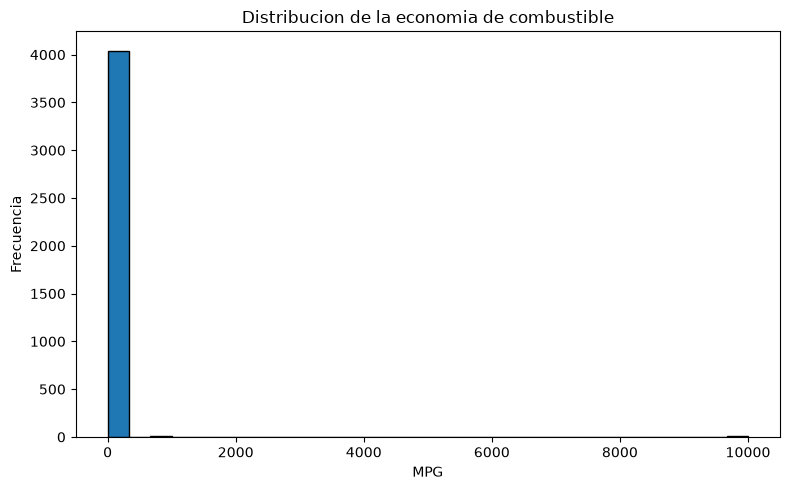

In [12]:
col_mpg = "RND_ADJ_FE"

graficar_histograma(df, col_mpg, "Distribucion de la economia de combustible", "MPG")


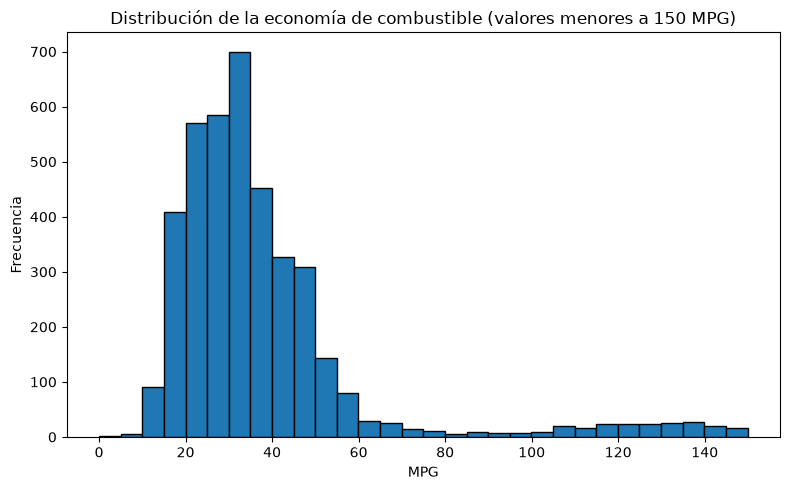

In [13]:
# Distribución de la economía de combustible mejor visualizada 

graficar_histograma(df, col_mpg, "Distribución de la economía de combustible (valores menores a 150 MPG)", "MPG", limite=150)

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de la Potencia </strong>
</div>

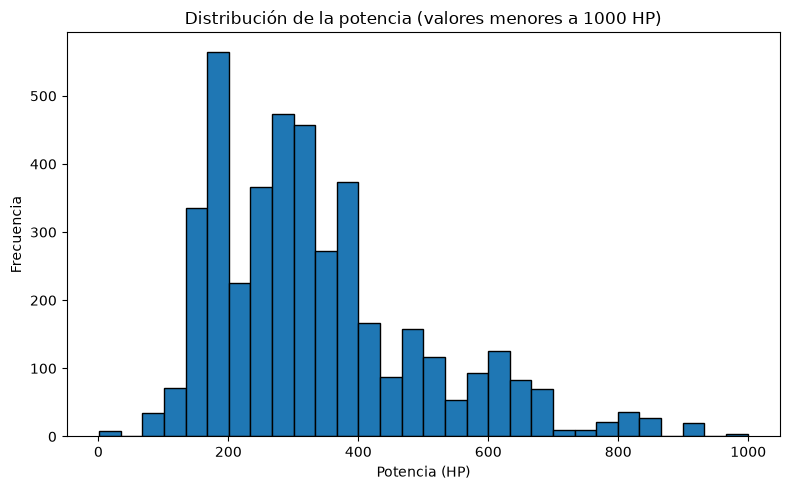

In [14]:
col_hp = "Rated Horsepower"

graficar_histograma(df, col_hp, "Distribución de la potencia (valores menores a 1000 HP)", "Potencia (HP)", limite=1000)

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de la Cilindrada </strong>
</div>

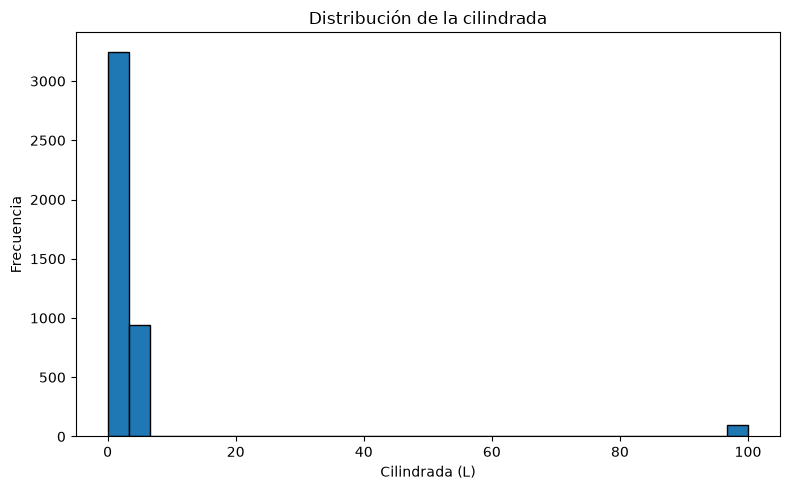

In [15]:
col_cilindrada = "Test Veh Displacement (L)"

graficar_histograma(df, col_cilindrada, "Distribución de la cilindrada", "Cilindrada (L)", None)



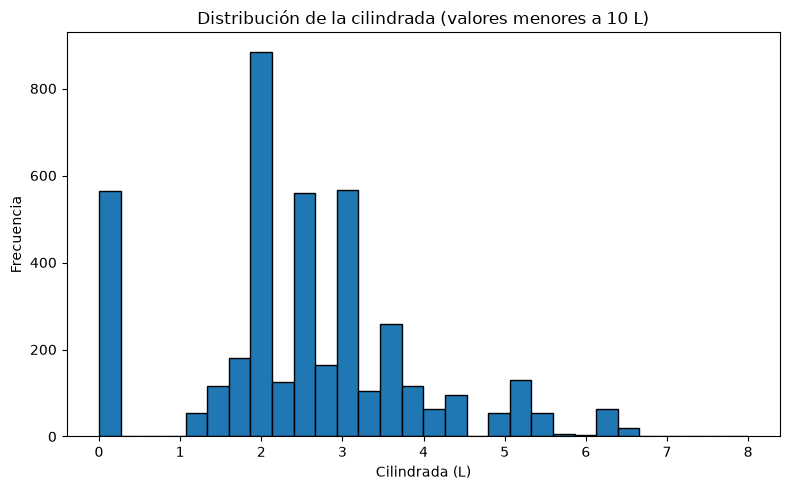

In [16]:
# Distribución de la cilindrada mejor visualizada

graficar_histograma(df, col_cilindrada, "Distribución de la cilindrada (valores menores a 10 L)", "Cilindrada (L)", limite=10)


<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion del Peso </strong>
</div>

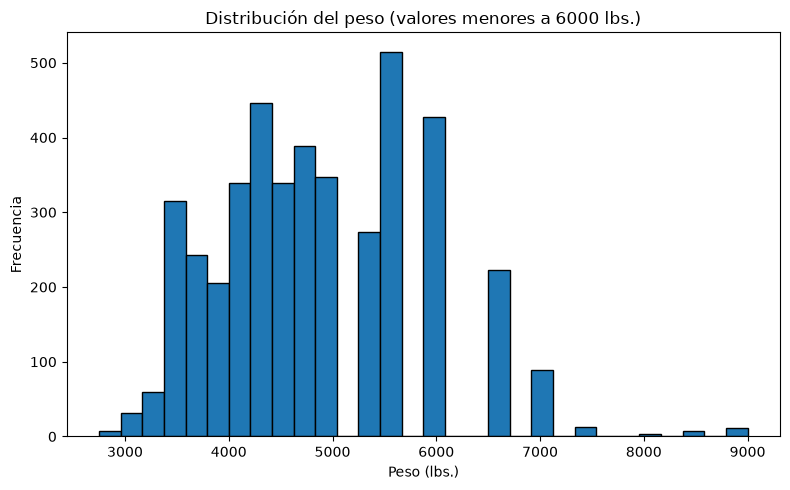

In [17]:
col_peso = "Equivalent Test Weight (lbs.)"

graficar_histograma(df, col_peso, "Distribución del peso (valores menores a 6000 lbs.)", "Peso (lbs.)", None)

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de los Sistemas de Traccion </strong>
</div>

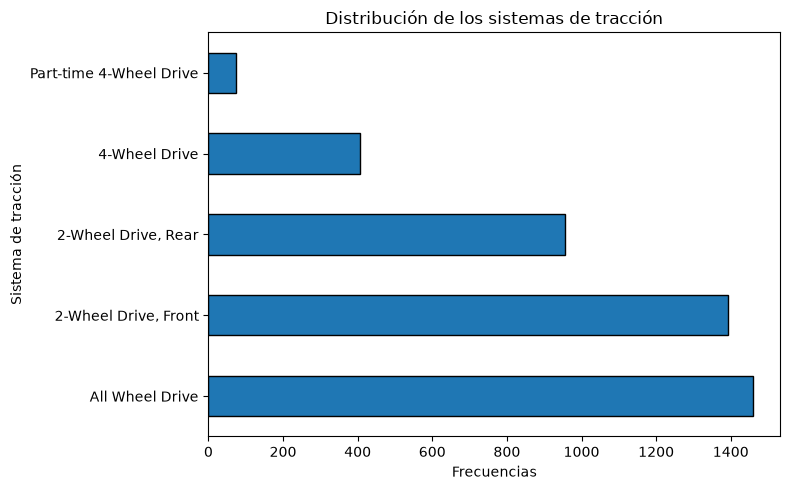

In [18]:
col_sistema_traccion = "Drive System Description"

graficar_barras(df, col_sistema_traccion, "Distribución de los sistemas de tracción", ylabel="Sistema de tracción", orientacion="horizontal", ordenar_indice=False)


<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de los Tipos de Transmision </strong>
</div>

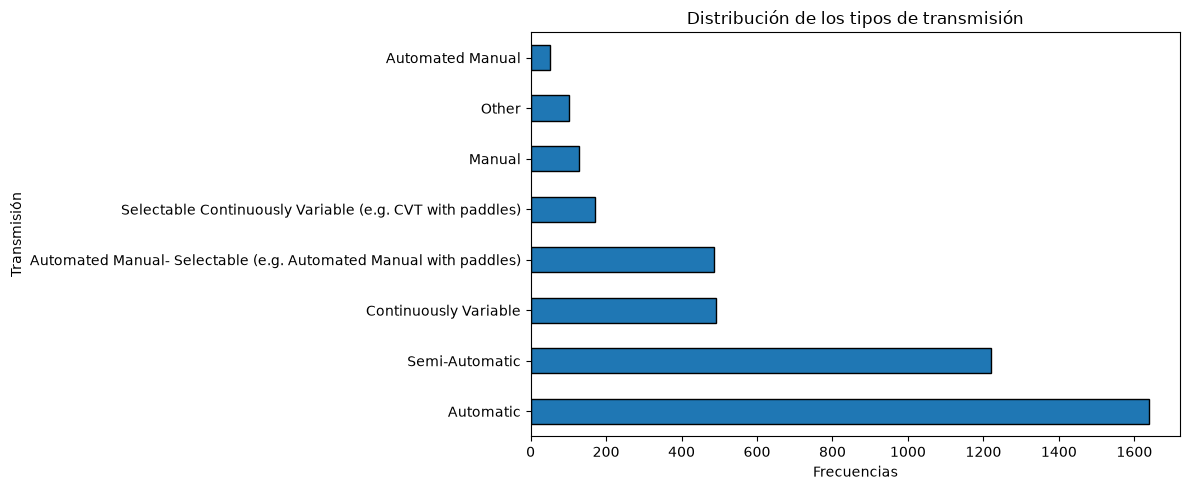

In [19]:
col_transmision = "Tested Transmission Type"

graficar_barras(df, col_transmision, "Distribución de los tipos de transmisión", ylabel="Transmisión", orientacion="horizontal", ordenar_indice=False, figsize=(12,5))

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de la Cantidad de Cilindros </strong>
</div>

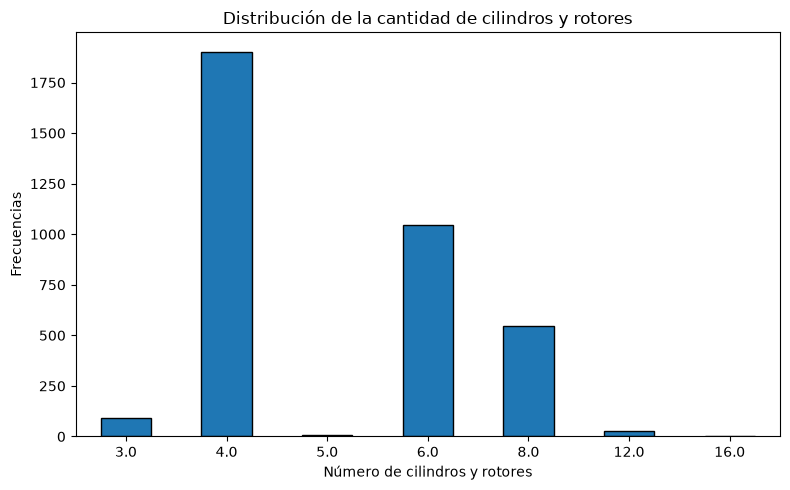

In [20]:
col_cantCilindros = "# of Cylinders and Rotors"

graficar_barras(df, col_cantCilindros, "Distribución de la cantidad de cilindros y rotores", ylabel="Número de cilindros y rotores", orientacion="vertical", ordenar_indice=True)

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de los Tipos de Combustible </strong>
</div>

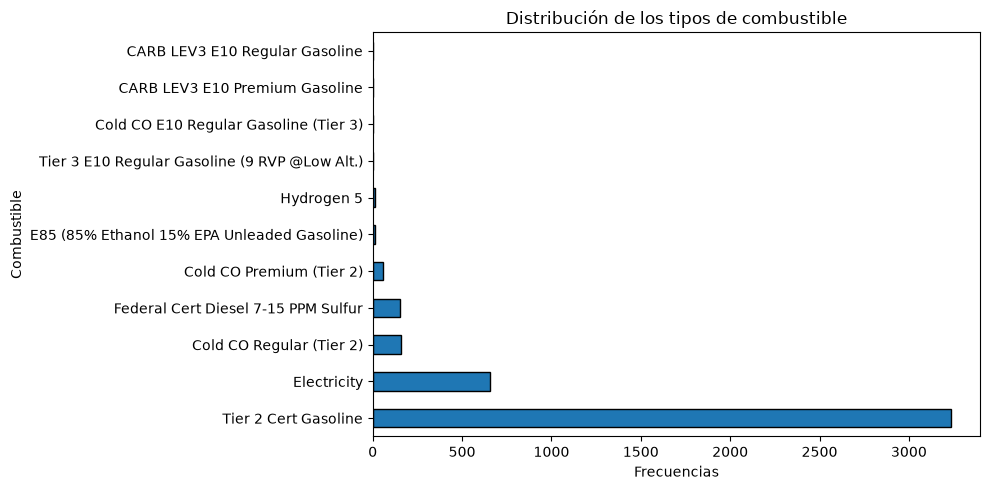

In [21]:
col_combustible = "Test Fuel Type Description"

graficar_barras(df, col_combustible, "Distribución de los tipos de combustible", ylabel="Combustible", orientacion="horizontal", ordenar_indice=False, figsize=(10,5))

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion del Tipo de Vehiculo </strong>
</div>

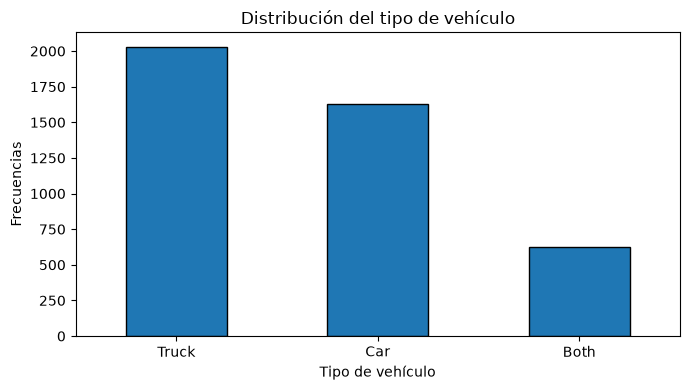

In [22]:
col_tipoVehiculo = "Vehicle Type"

graficar_barras(df, col_tipoVehiculo, "Distribución del tipo de vehículo", ylabel="Tipo de vehículo", orientacion="vertical", ordenar_indice=False, figsize=(7, 4))

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de la Relacion de Ejes </strong>
</div>

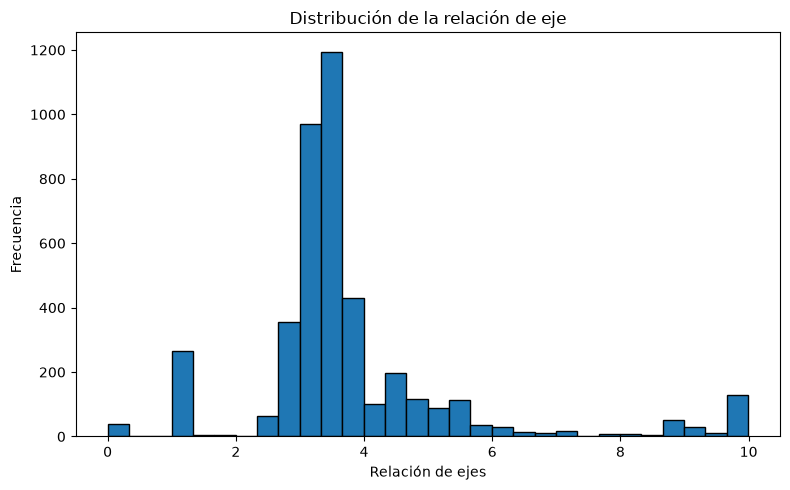

In [23]:

col_axleRatio = "Axle Ratio"

graficar_histograma(df, col_axleRatio, "Distribución de la relación de eje", "Relación de ejes", None)


<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de Emisiones de CO2 </strong>
</div>

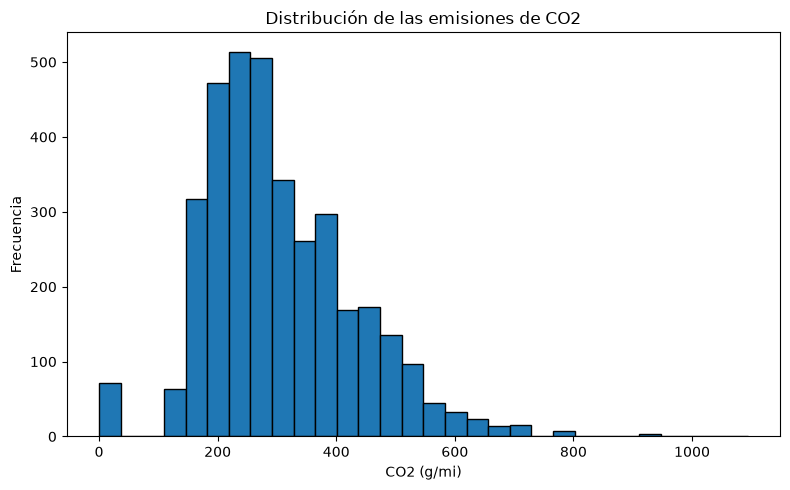

In [24]:

col_co2 = "CO2 (g/mi)"

graficar_histograma(df, col_co2, "Distribución de las emisiones de CO2", col_co2, None)

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de los Procesos de Prueba </strong>
</div>

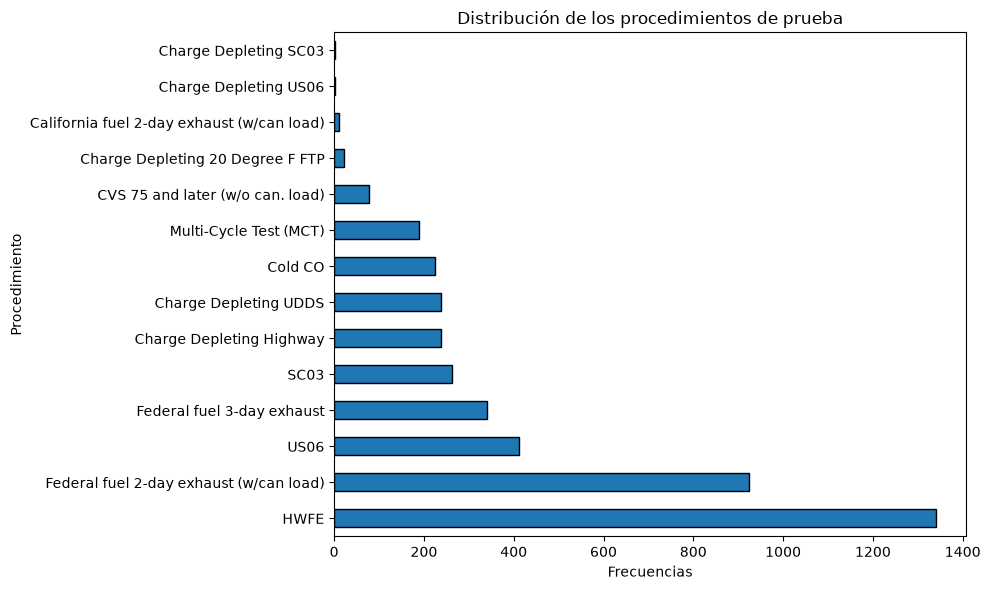

In [25]:

col_testProced = "Test Procedure Description"

graficar_barras(df, col_testProced, "Distribución de los procedimientos de prueba", ylabel="Procedimiento", orientacion="horizontal", ordenar_indice=False, figsize=(10,6))

<div style="background-color: #71aa95; padding: 10px; border-left: 5px solid #054f30; border-radius: 4px; color: #040404;"> 
<strong> Distribucion de la Cantidad de Marchas </strong>
</div>

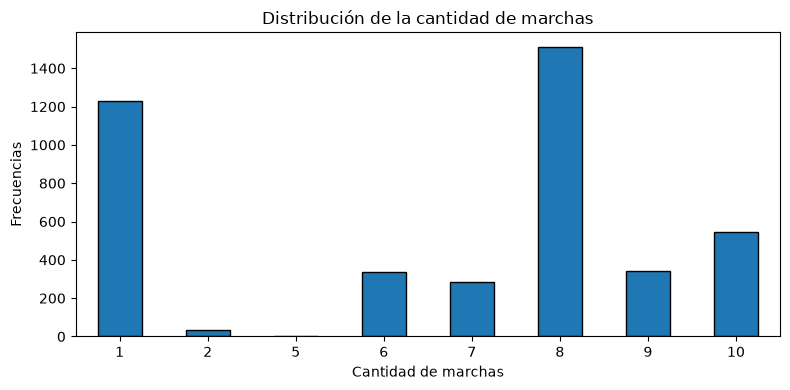

In [26]:
col_marchas = "# of Gears"

graficar_barras(df, col_marchas, "Distribución de la cantidad de marchas", ylabel="Cantidad de marchas", orientacion="vertical", ordenar_indice=True, figsize=(8, 4))


---
#
## ***Outliers***
#

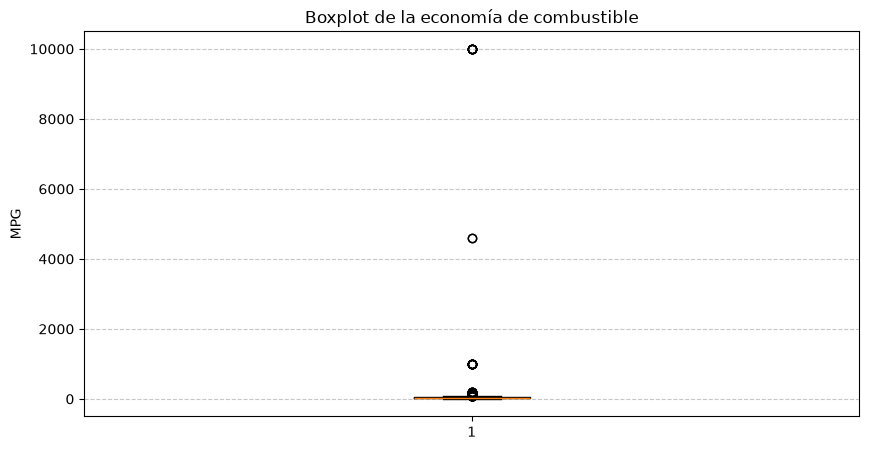

,RND_ADJ_FE
0,18.3
1,31.3
2,18.5
3,27.2
4,16.4
...,...
4274,44.5
4275,32.8
4280,43.6
4281,34.4


In [27]:
#Visualizamos los outliers de la economia de combustible

plt.figure(figsize=(10, 5))
plt.boxplot(df[col_mpg].dropna())

plt.title("Boxplot de la economía de combustible")
plt.ylabel("MPG")
plt.grid(axis='y', linestyle='--', alpha=0.7) 

plt.show()

df.loc[df[col_mpg] > 10, [col_mpg]] 



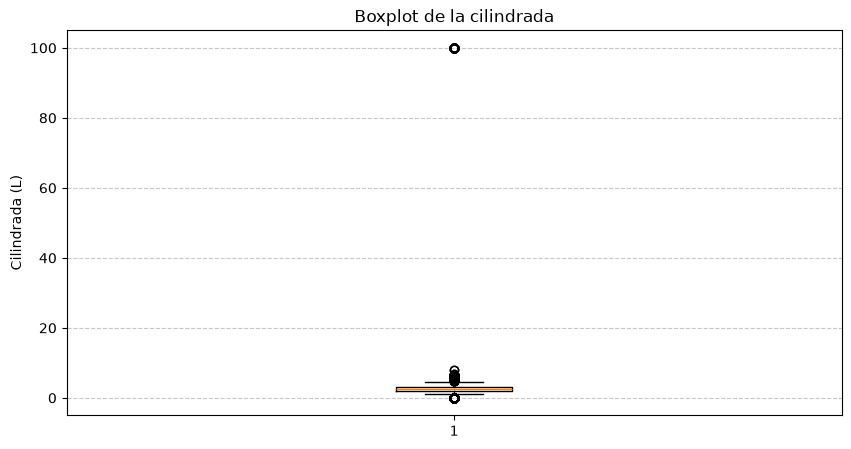

,Test Veh Displacement (L)
2881,99.999
2882,99.999
2883,99.999
2884,99.999
2885,99.999
...,...
3247,99.999
3248,99.999
3249,99.999
3250,99.999


In [28]:
#Visualizamos los outliers de la cilindrada

plt.figure(figsize=(10, 5))
plt.boxplot(df[col_cilindrada].dropna())

plt.title("Boxplot de la cilindrada")
plt.ylabel("Cilindrada (L)")
plt.grid(axis='y', linestyle='--', alpha=0.7) 

plt.show()


df.loc[df[col_cilindrada] > 10, [col_cilindrada]] 


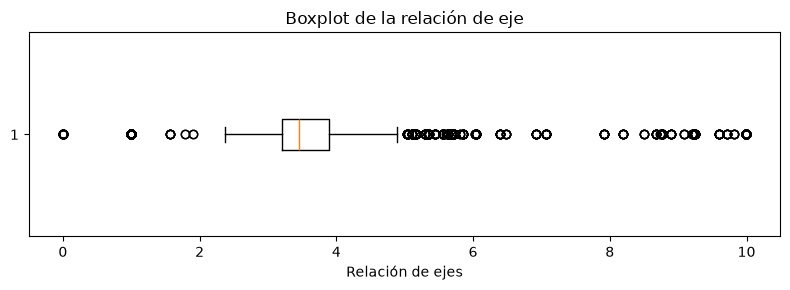

Valores nulos en la relación de eje: 0
Cantidad de valores distintos en la relación de eje: 162


count    4287.000000
mean        3.784444
std         1.718661
min         0.000000
25%         3.200000
50%         3.450000
75%         3.900000
max         9.990000
Name: Axle Ratio, dtype: float64

In [29]:
#Visualizamos los outliers de la Relacion de ejes

plt.figure(figsize=(8, 3))

plt.boxplot(df[col_axleRatio].dropna(), orientation='horizontal')

plt.title("Boxplot de la relación de eje")
plt.xlabel("Relación de ejes")
plt.tight_layout()
plt.show()

print("Valores nulos en la relación de eje:", df[col_axleRatio].isna().sum())
print("Cantidad de valores distintos en la relación de eje:", df[col_axleRatio].nunique())

display(df[col_axleRatio].describe())

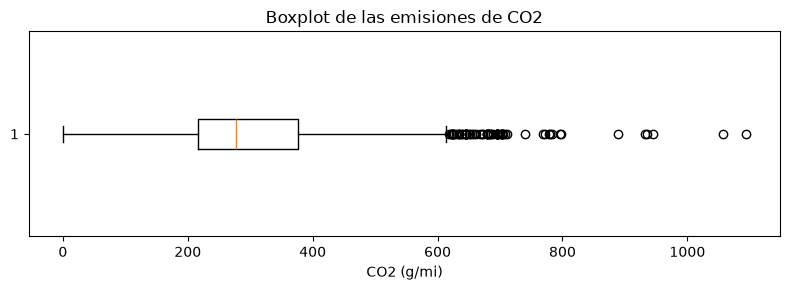

Valores nulos en las emisiones de CO2: 724
Valores iguales a 0 en las emisiones de CO2: 71
Valores negativos en las emisiones de CO2: 0


count    3563.000000
mean      304.229007
std       127.582740
min         0.000000
25%       215.814565
50%       277.000000
75%       376.662400
max      1093.643465
Name: CO2 (g/mi), dtype: float64

In [30]:
#Visualizamos los outliers de las emisiones de CO2

plt.figure(figsize=(8, 3))

plt.boxplot(df[col_co2].dropna(), orientation='horizontal')

plt.title("Boxplot de las emisiones de CO2")
plt.xlabel(col_co2)
plt.tight_layout()
plt.show()

print("Valores nulos en las emisiones de CO2:", df[col_co2].isna().sum())
print("Valores iguales a 0 en las emisiones de CO2:", (df[col_co2] == 0).sum())
print("Valores negativos en las emisiones de CO2:", (df[col_co2] < 0).sum())

display(df[col_co2].describe())

---
#
> # ***Ejericicio 2***
##
Limpieza: de variables (Cilindrada, MPG, Potencia, Tipo de Combustible, Relacion de Ejes, Emision de CO2, Procesos de Prueba), Nulos, Filas Duplicadas y Columnas innecesarias

In [31]:
#primero creamaos una copia del dataframe original para no perder los datos originales

df_limpio = df.copy()

print("Filas originales:", df.shape[0])
print("Columnas originales:", df.shape[1]) 

print("Filas para limpiar:", df_limpio.shape[0])
print("Columnas para limpiar:", df_limpio.shape[1])

Filas originales: 4287
Columnas originales: 67
Filas para limpiar: 4287
Columnas para limpiar: 67


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Variable: Cilindrada </strong>
</div>


In [32]:
#Analizamos la cantidad de outliers de la variable cilindrada

col_cilindrada = 'Test Veh Displacement (L)'

print("Valor 99.999:", (df_limpio[col_cilindrada] == 99.999).sum())
print("Valor 99.990:", (df_limpio[col_cilindrada] == 99.990).sum())

valores_bajos = (
    df_limpio[col_cilindrada].notna()
    & (df_limpio[col_cilindrada] < 0.1)
)
print("Valores menores a 0.1:", valores_bajos.sum())

Valor 99.999: 95
Valor 99.990: 2
Valores menores a 0.1: 565


In [33]:
#Investigar los posibles valores centinelas de la variable cilindrada

valores_centinelas = (
    df_limpio[col_cilindrada].isin([99.999, 99.990]) | 
    (
        df_limpio[col_cilindrada].notna()
        & (df_limpio[col_cilindrada] < 0.1)
    )
)

columnas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_cilindrada,
    col_combustible
]

print("\n-- Cantidad por valor --")
print(df_limpio.loc[valores_centinelas, col_cilindrada].value_counts().sort_index())                                           

print("\n-- Filas a investigar --")
display(df_limpio.loc[valores_centinelas, columnas].drop_duplicates())


-- Cantidad por valor --
Test Veh Displacement (L)
0.001     518
0.010      47
99.990      2
99.999     95
Name: count, dtype: int64

-- Filas a investigar --


,Vehicle Manufacturer Name,Represented Test Veh Model,Test Veh Displacement (L),Test Fuel Type Description
144,BMW,Countryman SE ALL4 (18'' Wheels),0.001,Electricity
148,BMW,"Countryman SE ALL4 (19"" Wheels)",0.001,Electricity
150,BMW,i4 eDrive 35 Gran Coupe (18'' Wheels),0.001,Electricity
152,BMW,i4 eDrive 35 Gran Coupe (19'' Wheels),0.001,Electricity
156,BMW,i4 eDrive 40 Gran Coupe (18'' Wheels),0.001,Electricity
...,...,...,...,...
4227,Volvo,EX90 Twin Motor (21 Inch Wheels),0.001,Electricity
4263,Wuhan Lotus Cars Co,ELETRE R Long Range,0.001,Electricity
4269,Wuhan Lotus Cars Co,ELETRE R Performance,0.001,Electricity
4275,Wuhan Lotus Cars Co,ELETRE S Long Range,0.001,Electricity


In [34]:
#Asumiendo que estos valores son centinelas, los reemplazamos por NaN

valores_especiales = [0.001, 0.010, 99.990, 99.999]

df_limpio[col_cilindrada] = df_limpio[col_cilindrada].replace(valores_especiales,np.nan)


In [35]:
#Comprobamos que funciono la limpieza de los valores centinelas de la variable cilindrada

print("Nulos originales:", df[col_cilindrada].isna().sum())
print("Nulos después de limpiar:", df_limpio[col_cilindrada].isna().sum())


Nulos originales: 0
Nulos después de limpiar: 662


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Variable: Economia del Combustible </strong>
</div>

In [36]:
#Analizamos la cantidad de outliers de la variable economia de combustible

valores_sospechosos = ((df_limpio[col_mpg] >= 999) | (df_limpio[col_mpg] == 0))

columnas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_combustible,
    col_testProced,
    col_mpg
]

display(df_limpio.loc[valores_sospechosos, columnas])

print("MPG igual a 0:", (df_limpio[col_mpg] == 0).sum())
print("MPG igual a 999:", (df_limpio[col_mpg] == 999).sum())
print("MPG igual o superior a 999:",(df_limpio[col_mpg] >= 999).sum())

,Vehicle Manufacturer Name,Represented Test Veh Model,Test Fuel Type Description,Test Procedure Description,RND_ADJ_FE
1845,Honda,CR-V e:FCEV,Hydrogen 5,Charge Depleting UDDS,0.0
1847,Honda,CR-V e:FCEV,Hydrogen 5,Charge Depleting Highway,0.0
2461,Lotus,Emira,Cold CO E10 Regular Gasoline (Tier 3),Cold CO,10000.0
2462,Lotus,Emira,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),SC03,10000.0
2463,Lotus,Emira,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),Federal fuel 2-day exhaust (w/can load),10000.0
2464,Lotus,Emira,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),HWFE,10000.0
2465,Lotus,Emira,CARB LEV3 E10 Regular Gasoline,SC03,10000.0
2466,Lotus,Emira,Cold CO E10 Regular Gasoline (Tier 3),Cold CO,10000.0
2467,"Lucid USA, Inc",Air Sapphire AWD,Electricity,Charge Depleting UDDS,999.0
2468,"Lucid USA, Inc",Air Sapphire AWD,Electricity,Charge Depleting Highway,999.0


MPG igual a 0: 2
MPG igual a 999: 14
MPG igual o superior a 999: 24


In [37]:
#Remplazamos los valores sospechosos de la variable economia de combustible por NaN

valores_sospechosos = [               
    999,
    9999.9999999,
    4595.3,
    4599.1
]

df_limpio[col_mpg] = df_limpio[col_mpg].replace(valores_sospechosos, np.nan)

In [38]:
#Comprobamos que los valores centinelas fueron reemplazados por NaN
print("Nulos originales:", df[col_mpg].isna().sum())

print("Valores nulos despues de limpiar:", df_limpio[col_mpg].isna().sum())

print("Valores iguales a 999:",(df_limpio[col_mpg] == 999).sum())

print("Valores iguales a 9999.9999999:",(df_limpio[col_mpg] == 9999.9999999).sum())

print("Valores mayores a 1000:",(df_limpio[col_mpg] > 1000).sum())

Nulos originales: 221
Valores nulos despues de limpiar: 245
Valores iguales a 999: 0
Valores iguales a 9999.9999999: 0
Valores mayores a 1000: 0


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Variable: Potencia </strong>
</div>

In [39]:
# Analizamos los valores nulos y sospechosos de la variable potencia

analizar_nulos(df, col_hp)

print("Valores menores o iguales a 10:", (df_limpio[col_hp] <= 10 ).sum())

columnas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_combustible,
    col_testProced,
    col_cilindrada,
    col_hp
]

col_modelo = "Represented Test Veh Model"

#Este grafico nos muestra los modelos de bronco que tienen potencia 1 o 181, y nos permite ver si hay algun valor sospechoso en la potencia de estos modelos.
display(df.loc[df[col_modelo].str.contains("bronco", case=False, na=False)& df[col_hp].isin([1, 181]),columnas].sort_values([col_modelo, col_hp]))

Variable: Rated Horsepower
Cantidad de nulos: 0
Porcentaje de nulos: 0.0 %
Valores menores o iguales a 10: 8


,Vehicle Manufacturer Name,Represented Test Veh Model,Test Fuel Type Description,Test Procedure Description,Test Veh Displacement (L),Rated Horsepower
845,FOMOCO,BRONCO SPORT 4WD,Tier 2 Cert Gasoline,Federal fuel 2-day exhaust (w/can load),1.5,1
846,FOMOCO,BRONCO SPORT 4WD,Tier 2 Cert Gasoline,US06,1.5,1
847,FOMOCO,BRONCO SPORT 4WD,Tier 2 Cert Gasoline,HWFE,1.5,1
856,FOMOCO,BRONCO SPORT SASQUATCH,Tier 2 Cert Gasoline,Federal fuel 2-day exhaust (w/can load),1.5,1
857,FOMOCO,BRONCO SPORT SASQUATCH,Tier 2 Cert Gasoline,HWFE,1.5,1
858,FOMOCO,BRONCO SPORT SASQUATCH,Tier 2 Cert Gasoline,US06,1.5,1
850,FOMOCO,Bronco Sport Sasquatch,Tier 2 Cert Gasoline,US06,1.5,181
851,FOMOCO,Bronco Sport Sasquatch,Tier 2 Cert Gasoline,US06,1.5,181
852,FOMOCO,Bronco Sport Sasquatch,Tier 2 Cert Gasoline,Federal fuel 2-day exhaust (w/can load),1.5,181
853,FOMOCO,Bronco Sport Sasquatch,Tier 2 Cert Gasoline,Federal fuel 2-day exhaust (w/can load),1.5,181


In [40]:
#Limpiamos los datos de la variable potencia, reemplazando los valores menores o iguales a 10 por NaN

df_limpio[col_hp] = df_limpio[col_hp].mask(df_limpio[col_hp] <= 10, np.nan)

In [41]:
#Comprobamos que los valores fueron reemplazados por NaN

print("Valores nulos después del reemplazo:\n")

analizar_nulos(df_limpio, col_hp)

print("\nValores iguales a 1 después del reemplazo:", (df_limpio[col_hp] ==1 ).sum())


Valores nulos después del reemplazo:

Variable: Rated Horsepower
Cantidad de nulos: 8
Porcentaje de nulos: 0.19 %

Valores iguales a 1 después del reemplazo: 0


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Variable: Tipos de Combustible </strong>
</div>

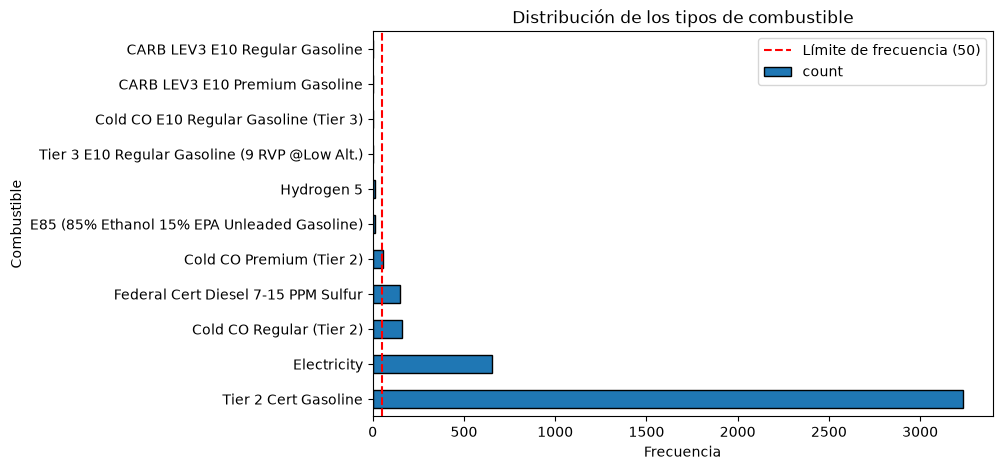

In [42]:

plt.figure(figsize=(8,5))

df[col_combustible].value_counts().plot(kind="barh", edgecolor="black") 

plt.xlabel("Frecuencia")
plt.ylabel("Combustible")
plt.title("Distribución de los tipos de combustible")
plt.axvline(x=50, color='red', linestyle='--', label='Límite de frecuencia (50)')  # Línea vertical en x=50
plt.legend()

plt.show()



In [43]:
#Cantidad de valores distintos de la variable tipo de combustible

display(df_limpio[col_combustible].value_counts())

Test Fuel Type Description
Tier 2 Cert Gasoline                             3236
Electricity                                       654
Cold CO Regular (Tier 2)                          160
Federal Cert Diesel 7-15 PPM Sulfur               150
Cold CO Premium (Tier 2)                           57
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Hydrogen 5                                         10
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
Cold CO E10 Regular Gasoline (Tier 3)               2
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

In [44]:
# Agrupar los tipos de combustible de tipo Gasolina en una sola categoría Gasolina

mapa_combustibles = {
    "Tier 2 Cert Gasoline": "Gasolina",
    "Cold CO Regular (Tier 2)": "Gasolina",
    "Cold CO Premium (Tier 2)": "Gasolina",
    "Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)": "Gasolina",
    "Cold CO E10 Regular Gasoline (Tier 3)": "Gasolina",
    "CARB LEV3 E10 Premium Gasoline": "Gasolina",
    "CARB LEV3 E10 Regular Gasoline": "Gasolina"
}

df_limpio["Tipo Combustible Agrupado"] = (                                              #creamos una columna nueva, no modificamos las que ya existen 
    df_limpio[col_combustible].replace(mapa_combustibles)
)

display(
    df_limpio["Tipo Combustible Agrupado"].value_counts()
)


Tipo Combustible Agrupado
Gasolina                                       3461
Electricity                                     654
Federal Cert Diesel 7-15 PPM Sulfur             150
E85 (85% Ethanol 15% EPA Unleaded Gasoline)      12
Hydrogen 5                                       10
Name: count, dtype: int64

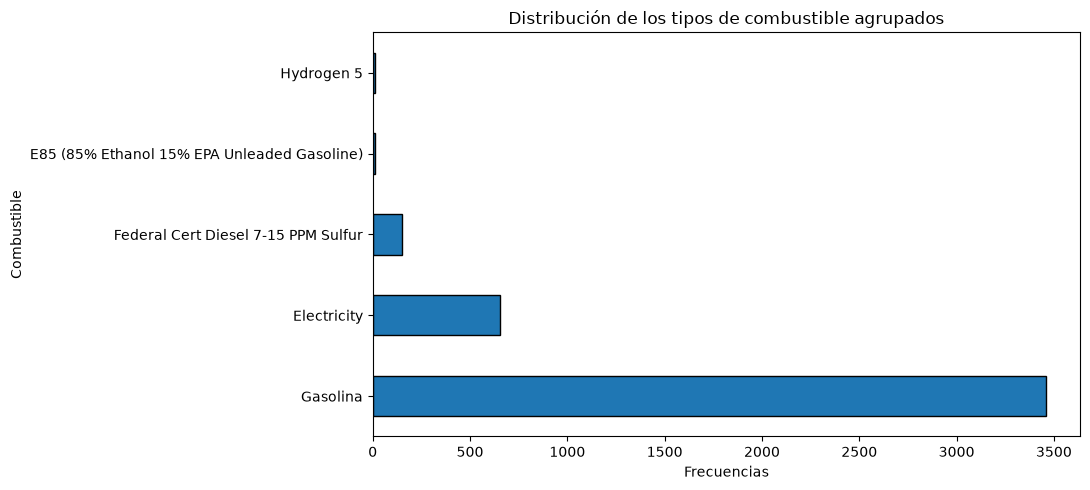

In [45]:

graficar_barras(df_limpio, "Tipo Combustible Agrupado", "Distribución de los tipos de combustible agrupados", ylabel="Combustible", orientacion="horizontal", ordenar_indice=False, figsize=(11,5))

<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Variable: Relacion de Ejes </strong>
</div>

In [46]:
print("Nulos:", df[col_axleRatio].isna().sum())
print("Valores iguales a 0:", (df[col_axleRatio] == 0).sum())
print("Valores menores que 1:", (df[col_axleRatio] < 1).sum())
print("Valores mayores que 6:", (df[col_axleRatio] > 6).sum())

columnas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_combustible,
    col_cilindrada,
    col_axleRatio
]

display(df.loc[(df[col_axleRatio] < 1) | (df[col_axleRatio] > 6), columnas].sort_values(col_axleRatio))

Nulos: 0
Valores iguales a 0: 38
Valores menores que 1: 38
Valores mayores que 6: 310


,Vehicle Manufacturer Name,Represented Test Veh Model,Test Fuel Type Description,Test Veh Displacement (L),Axle Ratio
2881,Nissan,ARIYA ENGAGE,Electricity,99.999,0.00
2882,Nissan,ARIYA ENGAGE,Electricity,99.999,0.00
2886,Nissan,ARIYA EVOLVE,Electricity,99.999,0.00
2885,Nissan,ARIYA EVOLVE,Electricity,99.999,0.00
3504,Toyota,RZ 300e (18inch Wheels),Electricity,0.001,0.00
...,...,...,...,...,...
3179,Rivian Automotive L,R1S All-Terrain Performance Dual Large (20in),Electricity,99.999,9.99
3178,Rivian Automotive L,R1S All-Terrain Performance Dual Large (20in),Electricity,99.999,9.99
3177,Rivian Automotive L,R1S All-Terrain Performance Dual Large (20in),Electricity,99.999,9.99
3176,Rivian Automotive L,R1S All-Terrain Performance Dual Large (20in),Electricity,99.999,9.99


In [47]:
# Queremos ver la cantidad de registros con relación de ejes igual a 0 y mayor a 6, y el tipo de combustible que tienen esos registros
print("Combustible de los registros con relación igual a 0:")
display(df.loc[df[col_axleRatio] == 0, col_combustible].value_counts(dropna=False))

print("Combustible de los registros con relación mayor a 6:")
display(df.loc[df[col_axleRatio] > 6, col_combustible].value_counts(dropna=False))

Combustible de los registros con relación igual a 0:


Test Fuel Type Description
Electricity    36
Hydrogen 5      2
Name: count, dtype: int64

Combustible de los registros con relación mayor a 6:


Test Fuel Type Description
Electricity                 264
Tier 2 Cert Gasoline         44
Cold CO Regular (Tier 2)      2
Name: count, dtype: int64

In [48]:
# Queremos si ademas de la relación de ejes igual a 0, tienen alguna otra característica en común, como el tipo de combustible, la potencia, la cilindrada o la cantidad de marchas

columnas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_combustible,
    col_cilindrada,
    col_hp,
    col_marchas,
    col_axleRatio,
]

display(df.loc[df[col_axleRatio] == 0, columnas])

,Vehicle Manufacturer Name,Represented Test Veh Model,Test Fuel Type Description,Test Veh Displacement (L),Rated Horsepower,# of Gears,Axle Ratio
2881,Nissan,ARIYA ENGAGE,Electricity,99.999,214,1,0.0
2882,Nissan,ARIYA ENGAGE,Electricity,99.999,214,1,0.0
2885,Nissan,ARIYA EVOLVE,Electricity,99.999,239,1,0.0
2886,Nissan,ARIYA EVOLVE,Electricity,99.999,239,1,0.0
3504,Toyota,RZ 300e (18inch Wheels),Electricity,0.001,98,1,0.0
3505,Toyota,RZ 300e (18inch Wheels),Electricity,0.001,98,1,0.0
3506,Toyota,RZ 300e (20inch Wheels),Electricity,0.001,98,1,0.0
3507,Toyota,RZ 300e (20inch Wheels),Electricity,0.001,98,1,0.0
3508,Toyota,RZ 450e AWD,Electricity,0.001,177,1,0.0
3509,Toyota,RZ 450e AWD,Electricity,0.001,177,1,0.0


In [49]:
# Reemplazamos por NaN los valores sospechosos
df_limpio[col_axleRatio] = df_limpio[col_axleRatio].replace(0, np.nan)


#Comprobamos que los valores fueron reemplazados por NaN
print("Nulos en Axle Ratio antes:")
analizar_nulos(df, col_axleRatio)
print("Valores iguales a 0 antes:", (df[col_axleRatio] == 0).sum())
print ("")
print("Nulos en Axle Ratio ahora:")
analizar_nulos(df_limpio, col_axleRatio)
print("Valores iguales a 0 ahora:", (df_limpio[col_axleRatio] == 0).sum())

Nulos en Axle Ratio antes:
Variable: Axle Ratio
Cantidad de nulos: 0
Porcentaje de nulos: 0.0 %
Valores iguales a 0 antes: 38

Nulos en Axle Ratio ahora:
Variable: Axle Ratio
Cantidad de nulos: 38
Porcentaje de nulos: 0.89 %
Valores iguales a 0 ahora: 0


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Variable: Emisiones de CO2 </strong>
</div>

In [50]:
print("Nulos en la variable CO2:")
analizar_nulos(df, col_co2)
print("\nValores iguales a 0:", (df[col_co2] == 0).sum())
print("Valores negativos:", (df[col_co2] < 0).sum())
print("Valores mayores que 800:", (df[col_co2] > 800).sum())

columnas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_combustible,
    col_co2
]

display(
    df.loc[df[col_co2] == 0, columnas]
)


Nulos en la variable CO2:
Variable: CO2 (g/mi)
Cantidad de nulos: 724
Porcentaje de nulos: 16.89 %

Valores iguales a 0: 71
Valores negativos: 0
Valores mayores que 800: 6


,Vehicle Manufacturer Name,Represented Test Veh Model,Test Fuel Type Description,CO2 (g/mi)
1076,GM,CELESTIQ,Electricity,0.0
1079,GM,CELESTIQ,Electricity,0.0
1453,GM,SILVERADO EV,Electricity,0.0
1456,GM,SILVERADO EV,Electricity,0.0
1463,GM,SILVERADO EV,Electricity,0.0
...,...,...,...,...
4279,Wuhan Lotus Cars Co,ELETRE S Long Range,Electricity,0.0
4282,Wuhan Lotus Cars Co,ELETRE S Performance,Electricity,0.0
4283,Wuhan Lotus Cars Co,ELETRE S Performance,Electricity,0.0
4284,Wuhan Lotus Cars Co,ELETRE S Performance,Electricity,0.0


In [51]:
# Investigamos las emisiones mas altas

columnas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_combustible,
    col_co2
]

display(df.loc[df[col_co2] > 800, columnas].sort_values(col_co2, ascending=False))

,Vehicle Manufacturer Name,Represented Test Veh Model,Test Fuel Type Description,CO2 (g/mi)
357,BMW,M5 Sedan,Tier 2 Cert Gasoline,1093.643465
371,BMW,M5 Touring,Tier 2 Cert Gasoline,1057.074100
360,BMW,M5 Sedan,Cold CO Premium (Tier 2),945.157600
4116,Volkswagen Group of,Bugatti Pur Sport,Tier 2 Cert Gasoline,935.000000
372,BMW,M5 Touring,Cold CO Premium (Tier 2),931.824900
492,BMW,XM Label,Cold CO Premium (Tier 2),888.765003


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Variable: Procesos de Prueba </strong>
</div>

In [52]:

print("Nulos de la variable procesos de prueba:")
analizar_nulos(df, col_testProced)
print("\nCantidad de procedimientos:", df[col_testProced].nunique())

display(df[col_testProced].value_counts(dropna=False))

Nulos de la variable procesos de prueba:
Variable: Test Procedure Description
Cantidad de nulos: 0
Porcentaje de nulos: 0.0 %

Cantidad de procedimientos: 14


Test Procedure Description
HWFE                                          1340
Federal fuel 2-day exhaust (w/can load)        923
US06                                           412
Federal fuel 3-day exhaust                     341
SC03                                           263
Charge Depleting Highway                       239
Charge Depleting UDDS                          237
Cold CO                                        224
Multi-Cycle Test (MCT)                         190
CVS 75 and later (w/o can. load)                78
Charge Depleting 20 Degree F FTP                23
California fuel 2-day exhaust (w/can load)      11
Charge Depleting US06                            3
Charge Depleting SC03                            3
Name: count, dtype: int64

<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Limpieza de Nulos </strong>
</div>

In [53]:
# Resumen de nulos, comparando el dataframe original con el dataframe limpio

variables_seleccionadas = [
    col_cilindrada,
    col_hp,
    col_cantCilindros,
    col_peso,
    col_marchas,
    col_transmision,
    col_sistema_traccion,
    col_combustible,
    col_mpg,
    col_tipoVehiculo,
    col_axleRatio,
    col_co2,
    col_testProced
]

resumen_nulos = pd.DataFrame({
    "Nulos originales": df[variables_seleccionadas].isna().sum(),
    "Nulos después de limpiar": df_limpio[variables_seleccionadas].isna().sum()
})

resumen_nulos["Nulos generados"] = (resumen_nulos["Nulos después de limpiar"] - resumen_nulos["Nulos originales"])

resumen_nulos["Porcentaje actual (%)"] = (resumen_nulos["Nulos después de limpiar"] / len(df_limpio) * 100).round(2)

display(resumen_nulos.sort_values("Nulos después de limpiar", ascending=False))

,Nulos originales,Nulos después de limpiar,Nulos generados,Porcentaje actual (%)
CO2 (g/mi),724,724,0,16.89
# of Cylinders and Rotors,670,670,0,15.63
Test Veh Displacement (L),0,662,662,15.44
RND_ADJ_FE,221,245,24,5.71
Axle Ratio,0,38,38,0.89
Rated Horsepower,0,8,8,0.19
Equivalent Test Weight (lbs.),0,0,0,0.00
# of Gears,0,0,0,0.00
Tested Transmission Type,0,0,0,0.00
Test Fuel Type Description,0,0,0,0.00


### ***Nulos en Cantidad de Cilindros***

In [54]:
#Comparar los nulos según el combustible de la variable cantidad de cilindros y rotores

porcentaje_nulos_combustible = (
    df.groupby(col_combustible)[col_cantCilindros]
    .apply(lambda serie: serie.isna().mean() * 100)
    .sort_values(ascending=False)
)

display(porcentaje_nulos_combustible.round(2))

Test Fuel Type Description
Electricity                                      100.00
Hydrogen 5                                       100.00
Tier 2 Cert Gasoline                               0.19
Cold CO E10 Regular Gasoline (Tier 3)              0.00
CARB LEV3 E10 Regular Gasoline                     0.00
CARB LEV3 E10 Premium Gasoline                     0.00
Cold CO Premium (Tier 2)                           0.00
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        0.00
Cold CO Regular (Tier 2)                           0.00
Federal Cert Diesel 7-15 PPM Sulfur                0.00
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)      0.00
Name: # of Cylinders and Rotors, dtype: float64

In [55]:
# Anlizamos esos casos donde la cantidad de cilindros es nula y el combustible es Gasolina

Variables_seleccionadas = [
    "Vehicle Manufacturer Name",
    "Represented Test Veh Model",
    col_cilindrada,
    col_hp,
    col_combustible,
    col_cantCilindros
]

display(df.loc[df[col_cantCilindros].isna() & (df[col_combustible] == "Tier 2 Cert Gasoline"), Variables_seleccionadas])

,Vehicle Manufacturer Name,Represented Test Veh Model,Test Veh Displacement (L),Rated Horsepower,Test Fuel Type Description,# of Cylinders and Rotors
8,BMW,230i Coupe,2.0,255,Tier 2 Cert Gasoline,NaN
9,BMW,230i Coupe,2.0,255,Tier 2 Cert Gasoline,NaN
2522,MAZDA,CX-5,2.5,187,Tier 2 Cert Gasoline,NaN
2523,MAZDA,CX-5,2.5,187,Tier 2 Cert Gasoline,NaN
2524,MAZDA,CX-5,2.5,187,Tier 2 Cert Gasoline,NaN
2525,MAZDA,CX-5,2.5,187,Tier 2 Cert Gasoline,NaN


### ***Nulos en Emisiones de CO2***

In [56]:

display(pd.crosstab(df[col_combustible],df[col_co2].isna(),margins=True)) # false = no es nulo, true = es nulo, margenes = True nos da la suma total

CO2 (g/mi),False,True,All
Test Fuel Type Description,,,
CARB LEV3 E10 Premium Gasoline,2,0,2
CARB LEV3 E10 Regular Gasoline,1,0,1
Cold CO E10 Regular Gasoline (Tier 3),2,0,2
Cold CO Premium (Tier 2),57,0,57
Cold CO Regular (Tier 2),160,0,160
E85 (85% Ethanol 15% EPA Unleaded Gasoline),12,0,12
Electricity,70,584,654
Federal Cert Diesel 7-15 PPM Sulfur,150,0,150
Hydrogen 5,0,10,10


In [57]:
# Registros de gasolina sin CO2 informado

filtro = (df[col_co2].isna() & (df[col_combustible] == "Tier 2 Cert Gasoline"))

df_co2_faltante = df.loc[filtro]

print("Cantidad de registros:", len(df_co2_faltante))
print("Cantidad de modelos diferentes:", df_co2_faltante["Represented Test Veh Model"].nunique())

display(df_co2_faltante[
        [
            "Vehicle Manufacturer Name",
            "Represented Test Veh Model",
            col_testProced,
            col_combustible,
            col_co2
        ]
    ]
)

Cantidad de registros: 130
Cantidad de modelos diferentes: 53


,Vehicle Manufacturer Name,Represented Test Veh Model,Test Procedure Description,Test Fuel Type Description,CO2 (g/mi)
107,BMW,550e xDrive Sedan,Charge Depleting UDDS,Tier 2 Cert Gasoline,NaN
108,BMW,550e xDrive Sedan,Charge Depleting Highway,Tier 2 Cert Gasoline,NaN
120,BMW,750e xDrive Sedan,Charge Depleting UDDS,Tier 2 Cert Gasoline,NaN
121,BMW,750e xDrive Sedan,Charge Depleting Highway,Tier 2 Cert Gasoline,NaN
358,BMW,M5 Sedan,Charge Depleting UDDS,Tier 2 Cert Gasoline,NaN
...,...,...,...,...,...
4241,Volvo,S90 T8 AWD Recharge Extended Range,Charge Depleting Highway,Tier 2 Cert Gasoline,NaN
4251,Volvo,XC60 T8 AWD Recharge Extended Range,Charge Depleting Highway,Tier 2 Cert Gasoline,NaN
4254,Volvo,XC60 T8 AWD Recharge Extended Range,Charge Depleting UDDS,Tier 2 Cert Gasoline,NaN
4259,Volvo,XC90 T8 AWD Recharge,Charge Depleting Highway,Tier 2 Cert Gasoline,NaN


In [58]:
# Analizamos los procedimientos de prueba de los registros de gasolina sin CO2 informado

display(df_co2_faltante[col_testProced].value_counts(dropna=False))


Test Procedure Description
Charge Depleting UDDS       65
Charge Depleting Highway    65
Name: count, dtype: int64

### ***Nulos en la Economia del Combustible***

In [59]:

display(pd.crosstab(df[col_combustible] , df[col_mpg].isna() , margins=True)) # falso = no es nulo, true = es nulo

RND_ADJ_FE,False,True,All
Test Fuel Type Description,,,
CARB LEV3 E10 Premium Gasoline,2,0,2
CARB LEV3 E10 Regular Gasoline,1,0,1
Cold CO E10 Regular Gasoline (Tier 3),2,0,2
Cold CO Premium (Tier 2),57,0,57
Cold CO Regular (Tier 2),160,0,160
E85 (85% Ethanol 15% EPA Unleaded Gasoline),12,0,12
Electricity,563,91,654
Federal Cert Diesel 7-15 PPM Sulfur,150,0,150
Hydrogen 5,10,0,10


In [60]:

df_mpg_faltante = df.loc[df[col_mpg].isna()]

display(pd.crosstab(df_mpg_faltante[col_testProced], df_mpg_faltante[col_combustible],margins=True))

Test Fuel Type Description,Electricity,Tier 2 Cert Gasoline,All
Test Procedure Description,,,
CVS 75 and later (w/o can. load),23,0,23
Charge Depleting Highway,0,65,65
Charge Depleting UDDS,0,65,65
Cold CO,3,0,3
HWFE,23,0,23
SC03,23,0,23
US06,19,0,19
All,91,130,221


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Filas Duplicadas </strong>
</div>

In [61]:
# Cantidad de filas completamente duplicadas
duplicados = df_limpio.duplicated().sum()

print("Filas duplicadas:", duplicados)

Filas duplicadas: 0


<div style="background-color: #8586b4; padding: 10px; border-left: 5px solid #085774; border-radius: 4px; color: #333;"> 
<strong> Columnas Innecesarias </strong>
</div>

In [62]:
variables_seleccionadas = [
    col_cilindrada,
    col_hp,
    col_cantCilindros,
    col_peso,
    col_marchas,
    col_transmision,
    col_sistema_traccion,
    col_combustible,
    col_mpg,
    col_tipoVehiculo,
    col_axleRatio,
    col_co2,
    col_testProced
]

print("Dimensiones del dataset de análisis:", df_limpio[variables_seleccionadas].shape)
display(df_limpio[variables_seleccionadas].head())

Dimensiones del dataset de análisis: (4287, 13)


,Test Veh Displacement (L),Rated Horsepower,# of Cylinders and Rotors,Equivalent Test Weight (lbs.),# of Gears,Tested Transmission Type,Drive System Description,Test Fuel Type Description,RND_ADJ_FE,Vehicle Type,Axle Ratio,CO2 (g/mi),Test Procedure Description
0,4.0,680.0,8.0,4500,8,Automatic,"2-Wheel Drive, Rear",Tier 2 Cert Gasoline,18.3,Car,3.08,484.329,Federal fuel 2-day exhaust (w/can load)
1,4.0,680.0,8.0,4500,8,Automatic,"2-Wheel Drive, Rear",Tier 2 Cert Gasoline,31.3,Car,3.08,283.235,HWFE
2,4.0,707.0,8.0,5500,9,Automatic,4-Wheel Drive,Tier 2 Cert Gasoline,18.5,Both,3.27,486.750,Federal fuel 2-day exhaust (w/can load)
3,4.0,707.0,8.0,5500,9,Automatic,4-Wheel Drive,Tier 2 Cert Gasoline,27.2,Both,3.27,331.480,HWFE
4,5.2,825.0,12.0,4500,8,Automatic,"2-Wheel Drive, Rear",Tier 2 Cert Gasoline,16.4,Car,2.93,546.351,Federal fuel 2-day exhaust (w/can load)


---
#
> # ***Ejercicio 4*** 
##
Evaluacion y validacion de hipótesis 
##


## 📌 **Parte 1: Validacion de Hipótesis Propias**

<div style="background-color: #b48593; padding: 10px; border-left: 5px solid #6f1e0c; border-radius: 4px; color: #333;"> 
<strong> Hipótesis 1 - Univariada
</div>

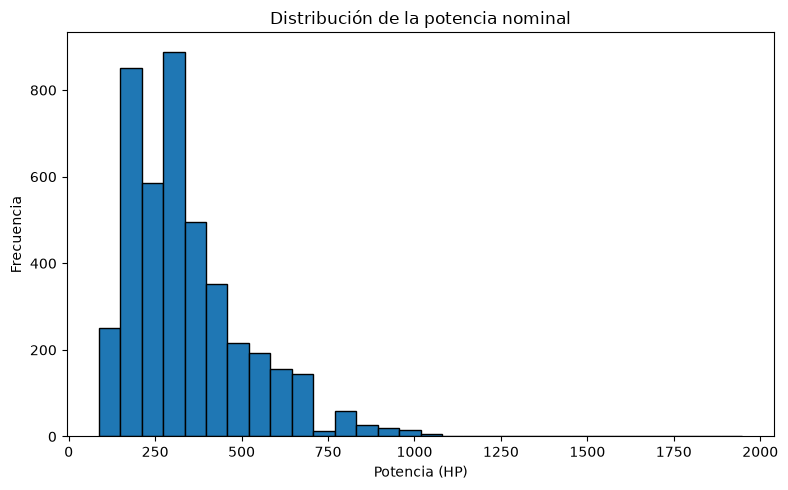

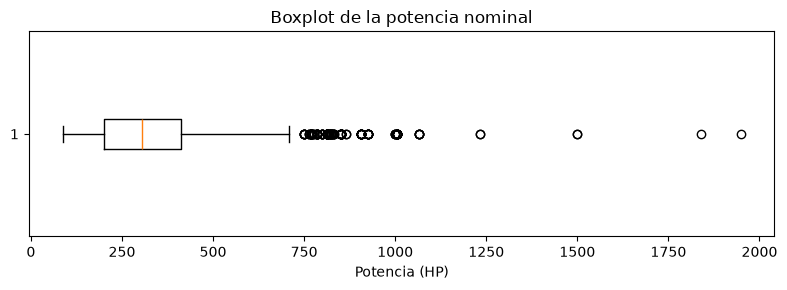

Media: 341.3332554335125
Mediana: 305.0
Asimetría: 1.6076685431878754


count    4279.000000
mean      341.333255
std       174.667461
min        87.000000
25%       201.000000
50%       305.000000
75%       412.000000
max      1948.000000
Name: Rated Horsepower, dtype: float64

In [95]:

# Histograma
graficar_histograma(df_limpio, col_hp, "Distribución de la potencia nominal", "Potencia (HP)")

#Boxplot
plt.figure(figsize=(8, 3))

plt.boxplot(df_limpio[col_hp].dropna(), orientation='horizontal')
plt.title("Boxplot de la potencia nominal")
plt.xlabel("Potencia (HP)")
plt.tight_layout()
plt.show()

#Estadistica Descriptiva
print("Media:", df_limpio[col_hp].mean())
print("Mediana:", df_limpio[col_hp].median())
print("Asimetría:", df_limpio[col_hp].skew())

display(df_limpio[col_hp].describe())

<div style="background-color: #b48593; padding: 10px; border-left: 5px solid #6f1e0c; border-radius: 4px; color: #333;"> 
<strong> Hipótesis 2 - Bivariada
</div>

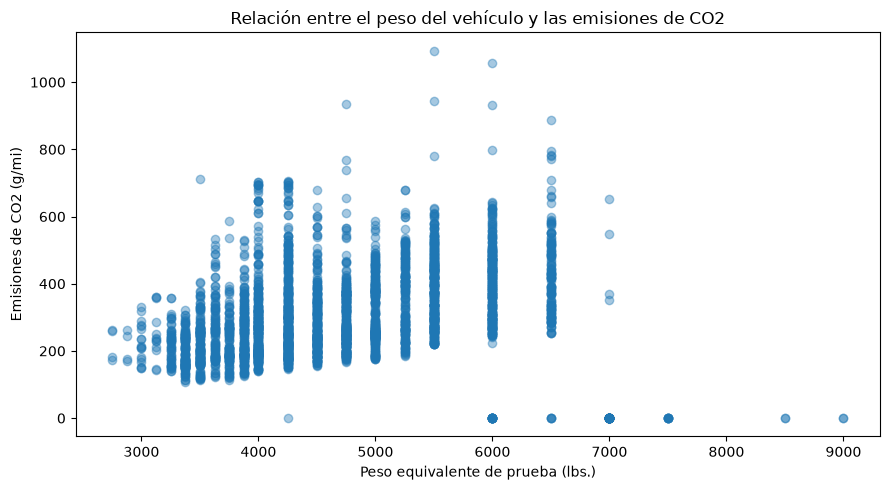

Cantidad de registros analizados: 3563
Correlación de Pearson: 0.317
Correlación de Spearman: 0.449


In [64]:

col_peso = col_peso
col_co2 = col_co2

# Seleccionamos los registros que tienen datos en ambas variables
datos = df_limpio[[col_peso, col_co2]].dropna()

# Diagrama de dispersión
plt.figure(figsize=(9, 5))

plt.scatter(
    datos[col_peso],
    datos[col_co2],
    alpha=0.4
)

plt.title("Relación entre el peso del vehículo y las emisiones de CO2")
plt.xlabel("Peso equivalente de prueba (lbs.)")
plt.ylabel("Emisiones de CO2 (g/mi)")
plt.tight_layout()
plt.show()

# Coeficientes de correlación
pearson = datos[col_peso].corr(datos[col_co2], method="pearson")
spearman = datos[col_peso].corr(datos[col_co2], method="spearman")

print("Cantidad de registros analizados:", len(datos))
print("Correlación de Pearson:", round(pearson, 3))
print("Correlación de Spearman:", round(spearman, 3))

<div style="background-color: #b48593; padding: 10px; border-left: 5px solid #6f1e0c; border-radius: 4px; color: #333;"> 
<strong> Hipótesis 3 - Multivariadas 
</div>

In [65]:
# Que registros se quedan afuera del analisis

variables_modelo = [
    col_mpg,
    col_peso,
    col_hp,
    col_cilindrada,
    col_cantCilindros,
    col_transmision,
    col_sistema_traccion
]

datos_modelo = df_limpio[variables_modelo].copy()

# Eliminamos los registros que tengan nulos en alguna de las variables
datos_modelo = datos_modelo.dropna()

print("Cantidad de registros originales:", len(df_limpio))
print("Cantidad de registros sin valores nulos:", len(datos_modelo))
print("Cantidad de registros eliminados:", len(df_limpio) - len(datos_modelo))

Cantidad de registros originales: 4287
Cantidad de registros sin valores nulos: 3471
Cantidad de registros eliminados: 816


#
## *Relacion entre cuantitativas*

In [ ]:
# Matriz de Correlación

variables_numericas = [
    col_mpg, 
    col_peso, 
    col_hp, 
    col_cilindrada, 
    col_cantCilindros
]

correlaciones = datos_modelo[variables_numericas].corr()

display(correlaciones.round(3)) 


,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors
RND_ADJ_FE,1.000,-0.513,-0.602,-0.546,-0.539
Equivalent Test Weight (lbs.),-0.513,1.000,0.441,0.510,0.536
Rated Horsepower,-0.602,0.441,1.000,0.754,0.829
Test Veh Displacement (L),-0.546,0.510,0.754,1.000,0.920
# of Cylinders and Rotors,-0.539,0.536,0.829,0.920,1.000


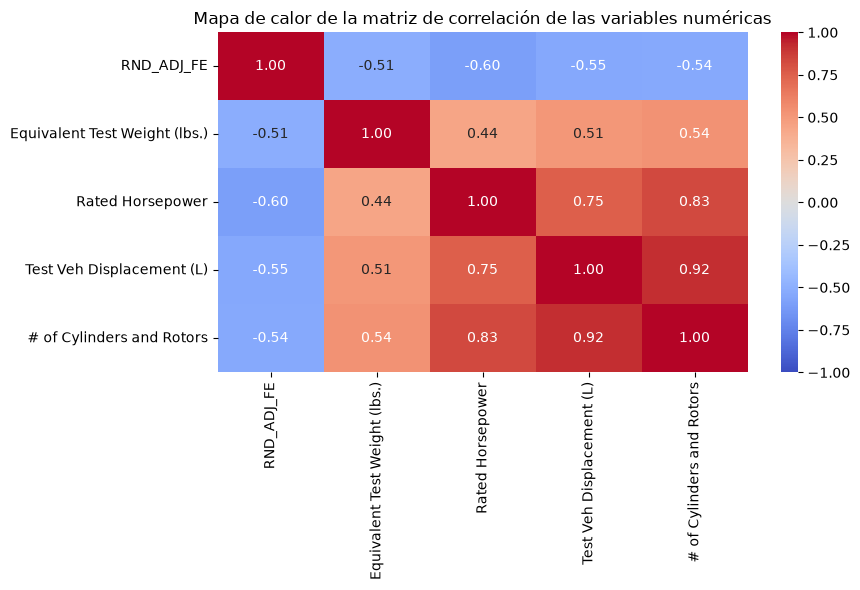

In [67]:
#mapa de calor de la matriz de correlación

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Mapa de calor de la matriz de correlación de las variables numéricas")
plt.tight_layout()
plt.show()

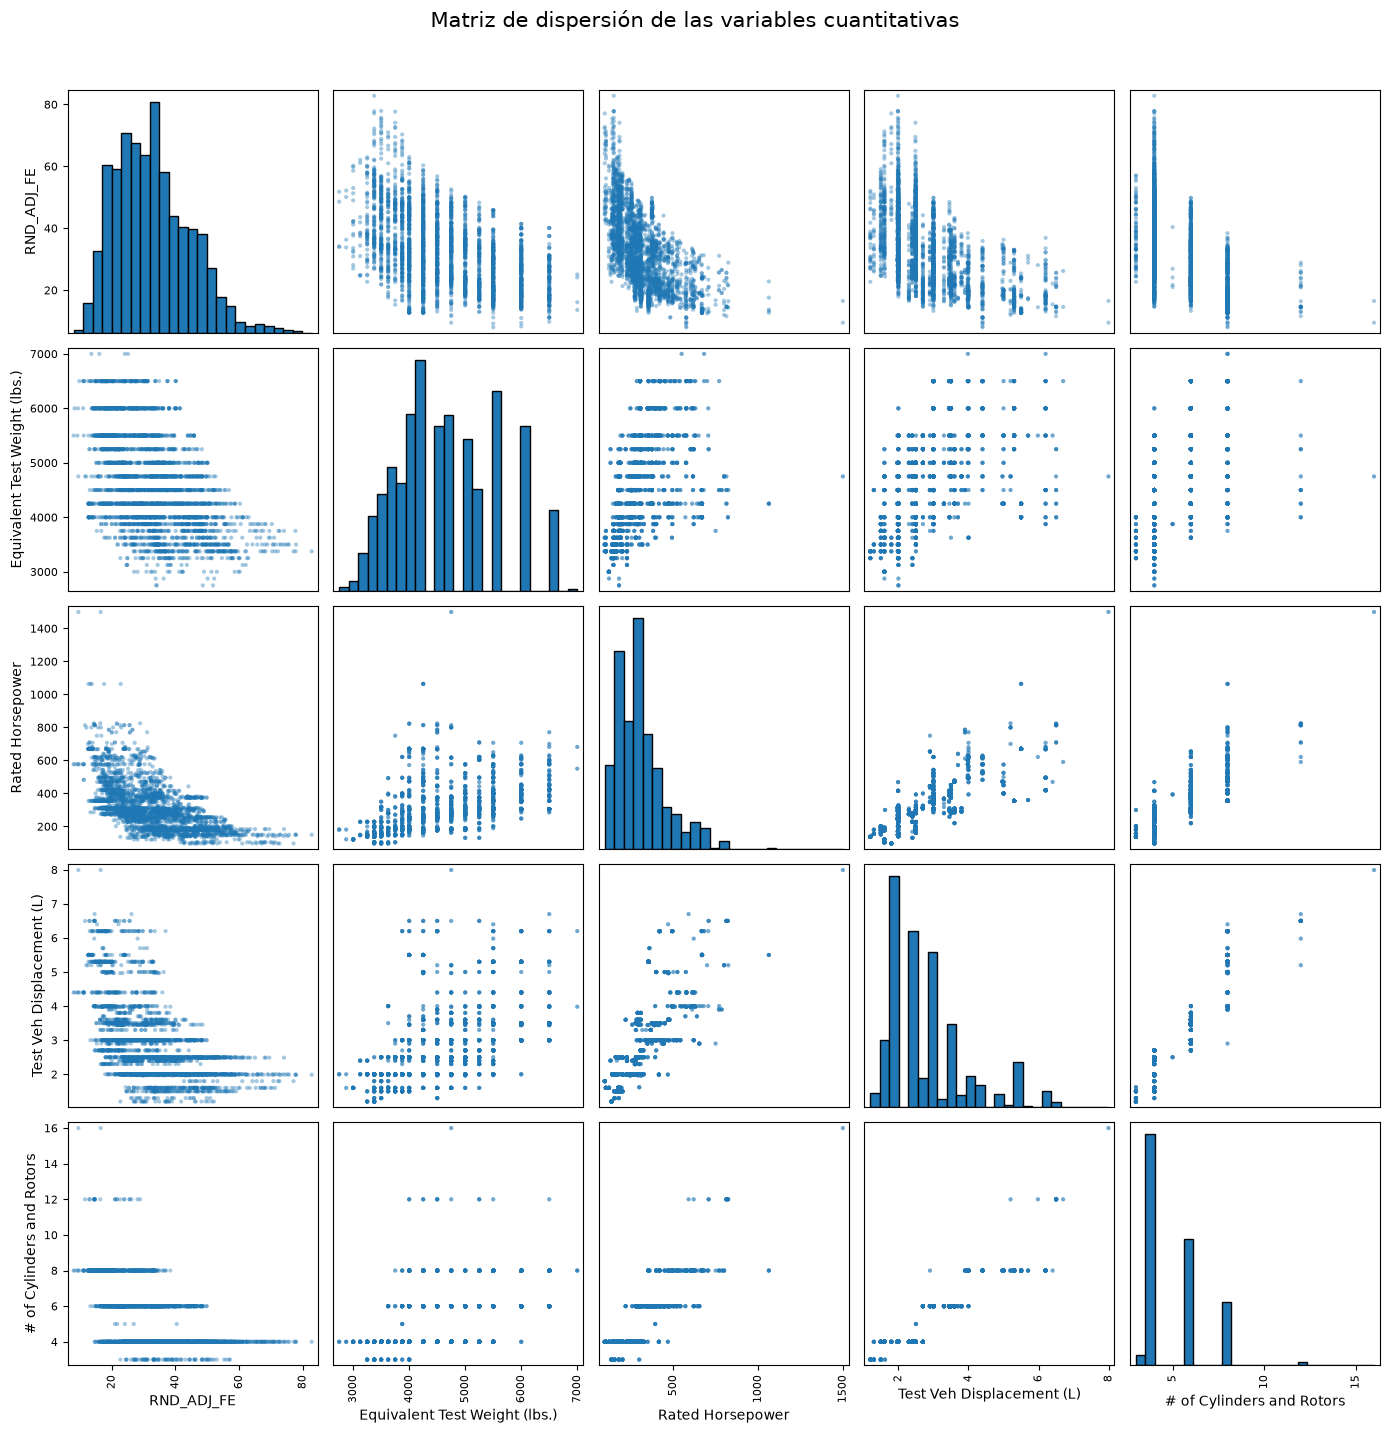

In [ ]:
#La matriz de dispersión muestra gráficamente las mismas relaciones que medimos con la correlación.

variables_cuantitativas = [
    col_mpg,
    col_peso,
    col_hp,
    col_cilindrada,
    col_cantCilindros
]

datos_scatter = df_limpio[variables_cuantitativas].copy()


datos_scatter = datos_scatter.dropna()


pd.plotting.scatter_matrix(
    datos_scatter,
    figsize=(14, 14),
    alpha=0.4,
    diagonal="hist",
    hist_kwds={"bins": 25, "edgecolor": "black"}
)

plt.suptitle(
    "Matriz de dispersión de las variables cuantitativas",
    y=1.02,
    fontsize=15
)

plt.tight_layout()
plt.show()

#
## *Regresion lineal multiple*


In [69]:
#Vemos el dataframe con las variables seleccionadas y sin datos nulos

display(datos_modelo.head())

,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description
0,18.3,4500,680.0,4.0,8.0,Automatic,"2-Wheel Drive, Rear"
1,31.3,4500,680.0,4.0,8.0,Automatic,"2-Wheel Drive, Rear"
2,18.5,5500,707.0,4.0,8.0,Automatic,4-Wheel Drive
3,27.2,5500,707.0,4.0,8.0,Automatic,4-Wheel Drive
4,16.4,4500,825.0,5.2,12.0,Automatic,"2-Wheel Drive, Rear"


In [70]:
# Transformamos las variables cualitativas en variables numéricas (One-Hot Encoding)
datos_modelo = pd.get_dummies(
    datos_modelo,
    columns=[
        col_transmision,
        col_sistema_traccion
    ],
    drop_first=True,
    dtype=int
)

display(datos_modelo.head())

print("Cantidad de columnas antes:", df_limpio[variables_modelo].shape[1])
print("Cantidad de columnas después:", datos_modelo.shape[1])

,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type_Automated Manual- Selectable (e.g. Automated Manual with paddles),Tested Transmission Type_Automatic,Tested Transmission Type_Continuously Variable,Tested Transmission Type_Manual,Tested Transmission Type_Selectable Continuously Variable (e.g. CVT with paddles),Tested Transmission Type_Semi-Automatic,"Drive System Description_2-Wheel Drive, Rear",Drive System Description_4-Wheel Drive,Drive System Description_All Wheel Drive,Drive System Description_Part-time 4-Wheel Drive
0,18.3,4500,680.0,4.0,8.0,0,1,0,0,0,0,1,0,0,0
1,31.3,4500,680.0,4.0,8.0,0,1,0,0,0,0,1,0,0,0
2,18.5,5500,707.0,4.0,8.0,0,1,0,0,0,0,0,1,0,0
3,27.2,5500,707.0,4.0,8.0,0,1,0,0,0,0,0,1,0,0
4,16.4,4500,825.0,5.2,12.0,0,1,0,0,0,0,1,0,0,0


Cantidad de columnas antes: 7
Cantidad de columnas después: 15


In [ ]:

# Separamos la variable dependiente de las explicativas
X = datos_modelo.drop(columns=[col_mpg])
y = datos_modelo[col_mpg]

X = sm.add_constant(X)

# Ajustamos la regresión lineal múltiple
modelo = sm.OLS(y, X).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.510
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     257.4
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:15:36   Log-Likelihood:                -12261.
No. Observations:                3471   AIC:                         2.455e+04
Df Residuals:                    3456   BIC:                         2.464e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                                                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

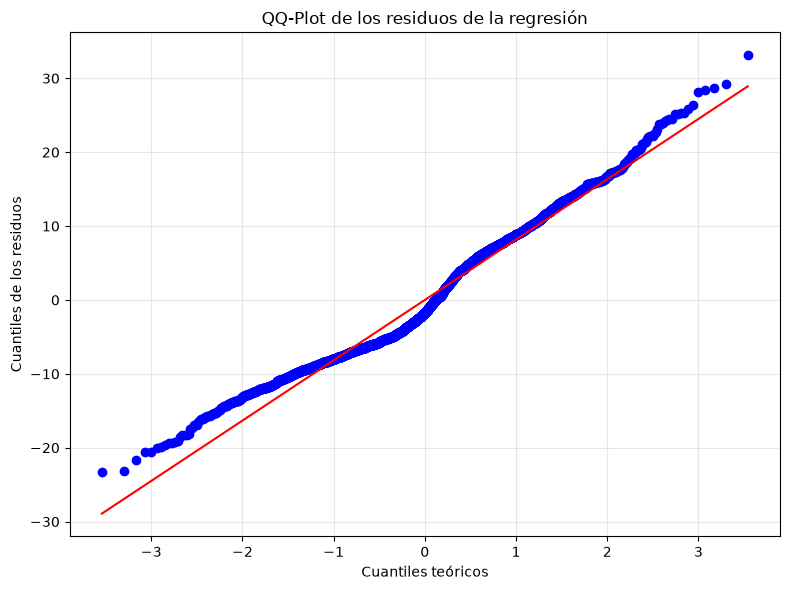

In [72]:
# Evaluamos cómo se distribuyen los residuos de nuestra regresión

# Obtenemos los residuos del modelo
residuos = modelo.resid

# Creamos el QQ-Plot
plt.figure(figsize=(8, 6))

stats.probplot(
    residuos,
    dist="norm",
    plot=plt
)

plt.title("QQ-Plot de los residuos de la regresión")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de los residuos")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

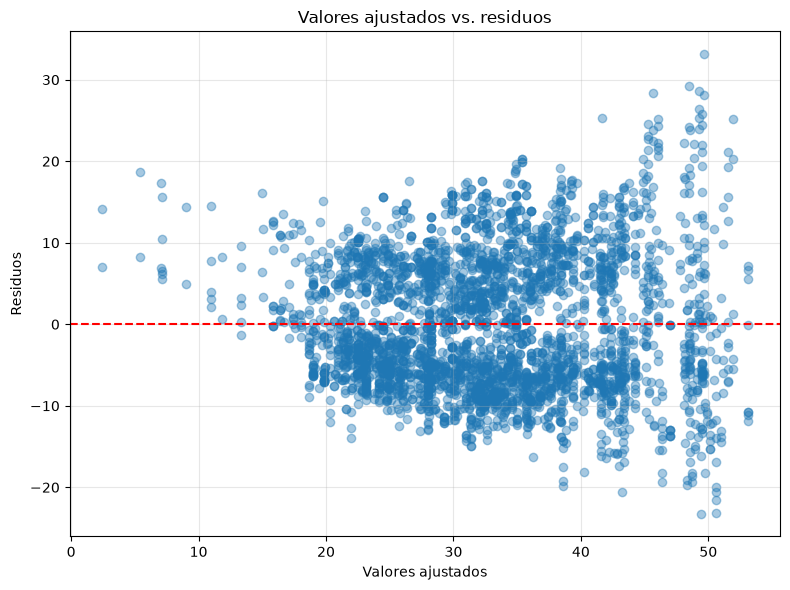

In [73]:
#valores ajustados vs. residuos

plt.figure(figsize=(8, 6))

plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.4)

plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores ajustados vs. residuos")

plt.axhline(0, color="red", linestyle="--")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 
## *Clustering*

In [ ]:

# Seleccionamos las variables explicativas, excluyendo MPG
datos_clustering = datos_modelo.drop(columns=[col_mpg])

# Normalizamos las variables
scaler = MinMaxScaler()

datos_clustering = pd.DataFrame(
    scaler.fit_transform(datos_clustering),
    columns=datos_clustering.columns,
    index=datos_clustering.index
)

display(datos_clustering.head())

,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type_Automated Manual- Selectable (e.g. Automated Manual with paddles),Tested Transmission Type_Automatic,Tested Transmission Type_Continuously Variable,Tested Transmission Type_Manual,Tested Transmission Type_Selectable Continuously Variable (e.g. CVT with paddles),Tested Transmission Type_Semi-Automatic,"Drive System Description_2-Wheel Drive, Rear",Drive System Description_4-Wheel Drive,Drive System Description_All Wheel Drive,Drive System Description_Part-time 4-Wheel Drive
0,0.411765,0.415538,0.412189,0.384615,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.411765,0.415538,0.412189,0.384615,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.647059,0.434783,0.412189,0.384615,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.647059,0.434783,0.412189,0.384615,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.411765,0.518888,0.588841,0.692308,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


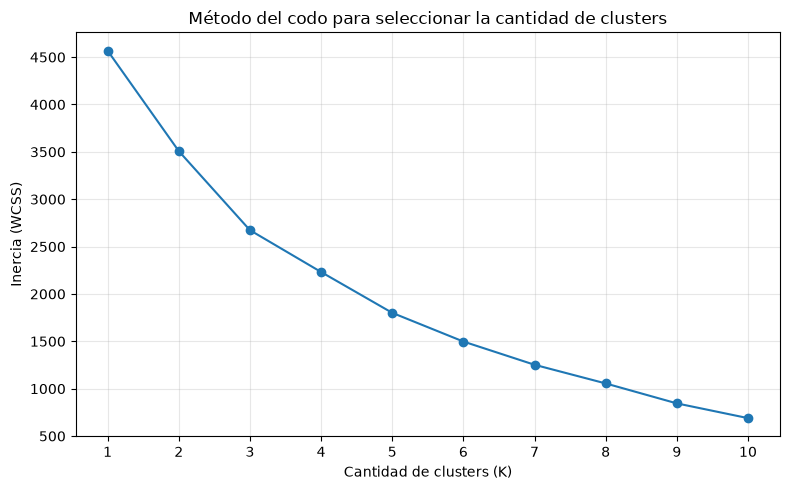

In [ ]:
#K-Means necesita que indiquemos previamente cuántos grupos queremos formar, pero no vamos a elegir un número arbitrario, sino que vamos a usar el método de Elbow plot para determinar el número óptimo de clusters.

inercias = []

# Probamos distintas cantidades de clusters
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(datos_clustering)

    inercias.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inercias, marker="o")

plt.title("Método del codo para seleccionar la cantidad de clusters")
plt.xlabel("Cantidad de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



No se distingue tan bien el codo 

In [ ]:
# Aplicamos K-Means con 5 clusters

kmeans = KMeans(
    n_clusters=5,
    random_state=42,                 
    n_init=10                                      
)

clusters = kmeans.fit_predict(datos_clustering)

# Guardamos el cluster asignado a cada vehículo
datos_modelo["Cluster"] = clusters

# Calculamos el coeficiente de silueta
silueta = silhouette_score(datos_clustering, clusters)

print("Coeficiente de silueta:", round(silueta, 4))

print("\nCantidad de vehículos en cada grupo:")
print(datos_modelo["Cluster"].value_counts().sort_index())


Coeficiente de silueta: 0.4335

Cantidad de vehículos en cada grupo:
Cluster
0     455
1     687
2     762
3    1026
4     541
Name: count, dtype: int64


In [96]:
# Variables cuantitativas originales
columnas_numericas = [
    col_mpg,
    col_peso,
    col_hp,
    col_cilindrada,
    col_cantCilindros
]

resumen_clusters = (
    datos_modelo.groupby("Cluster")[columnas_numericas].mean().round(2)
)

display(resumen_clusters)

# Seleccionamos las columnas correspondientes a las categorías
columnas_categoricas = [
    col for col in datos_modelo.columns
    if col.startswith("Tested Transmission Type_")
    or col.startswith("Drive System Description_")
]

# Calculamos el porcentaje de cada categoría por cluster
resumen_categorias = (
    datos_modelo.groupby("Cluster")[columnas_categoricas].mean().mul(100).round(1) 
)

display(resumen_categorias)

,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors
Cluster,,,,,
0,36.18,4131.32,284.66,2.27,4.54
1,43.94,3946.14,178.17,2.16,4.02
2,30.79,4817.42,354.11,2.99,5.60
3,28.42,5161.06,327.72,3.18,5.54
4,27.19,4638.17,420.39,3.52,6.07


,Tested Transmission Type_Automated Manual- Selectable (e.g. Automated Manual with paddles),Tested Transmission Type_Automatic,Tested Transmission Type_Continuously Variable,Tested Transmission Type_Manual,Tested Transmission Type_Selectable Continuously Variable (e.g. CVT with paddles),Tested Transmission Type_Semi-Automatic,"Drive System Description_2-Wheel Drive, Rear",Drive System Description_4-Wheel Drive,Drive System Description_All Wheel Drive,Drive System Description_Part-time 4-Wheel Drive
Cluster,,,,,,,,,,
0,100.0,0.0,0.0,0.0,0.0,0.0,7.0,5.7,39.1,0.0
1,0.0,0.0,68.6,6.0,24.6,0.0,1.5,1.7,0.6,0.9
2,0.0,0.0,0.0,0.7,0.0,96.7,0.0,9.1,55.9,3.4
3,0.0,100.0,0.0,0.0,0.0,0.0,25.0,20.0,34.9,0.2
4,0.0,0.0,0.0,14.4,0.0,82.3,100.0,0.0,0.0,0.0


---
#
## 📌 **Parte 2: Análisis de Hipótesis de la Cátedra**

<div style="background-color: #b48593; padding: 10px; border-left: 5px solid #6f1e0c; border-radius: 4px; color: #333;"> 
<strong> Hipótesis (a): " La mayoría de las configuraciones de vehículos a combustión alcanzan al
menos 25 MPG de economía de combustible en condiciones de conducción
urbana. "
</div>

In [78]:
df_limpio[col_combustible].value_counts(dropna=False)

Test Fuel Type Description
Tier 2 Cert Gasoline                             3236
Electricity                                       654
Cold CO Regular (Tier 2)                          160
Federal Cert Diesel 7-15 PPM Sulfur               150
Cold CO Premium (Tier 2)                           57
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Hydrogen 5                                         10
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
Cold CO E10 Regular Gasoline (Tier 3)               2
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

In [ ]:
combustibles_combustion = [
    "Tier 2 Cert Gasoline",
    "Federal Cert Diesel 7-15 PPM Sulfur",
    "Cold CO Regular (Tier 2)",
    "Cold CO Premium (Tier 2)",
    "E85 (85% Ethanol 15% EPA Unleaded Gasoline)"
]

# Filtramos vehículos a combustión y ensayos FTP en un nuevo df
df_urbano = df_limpio[
    (df_limpio[col_combustible].isin(combustibles_combustion)) &
    (df_limpio["Test Category"] == "FTP")
].copy()

# Eliminamos registros sin MPG válido 
df_urbano = df_urbano.dropna(subset=[col_mpg])

# agrupamos los registros que pertenecen a una misma configuración de vehículo y calculamos su MPG promedio.
df_urbano = (
    df_urbano.groupby(["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"], as_index=False)
    .agg(MPG_urbano=(col_mpg, "mean"))                                 
)

display(df_urbano)



,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,MPG_urbano
0,ASX,370TT7334,0,16.4
1,ASX,5723PT5601,0,18.3
2,ASX,6122PT6433,0,19.1
3,ASX,8841PT8473,0,18.5
4,BMX,2U74030,0,34.9
...,...,...,...,...
1079,VVX,202521,1,31.1
1080,VVX,202522,0,30.0
1081,VVX,202523,0,34.8
1082,VVX,202524,0,32.8


In [80]:
# Calculamos resultados
total = len(df_urbano)
cumplen = (df_urbano["MPG_urbano"] >= 25).sum()
proporcion = cumplen / total
porcentaje = proporcion * 100

print(f"Total de configuraciones: {total}")
print(f"Configuraciones con al menos 25 MPG: {cumplen}")
print(f"Porcentaje que cumple: {porcentaje:.2f}%")

# Evaluamos la hipótesis
if proporcion > 0.50:
    print("Se respalda H1.")
else:
    print("No se respalda H1.")

Total de configuraciones: 1084
Configuraciones con al menos 25 MPG: 655
Porcentaje que cumple: 60.42%
Se respalda H1.


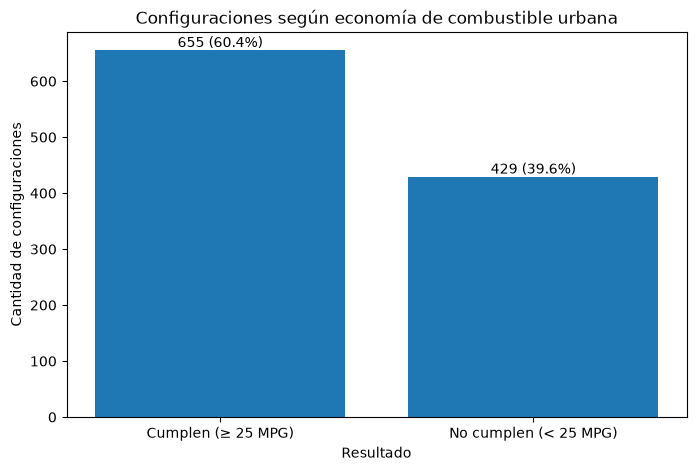

In [ ]:
#Lo visualizamos con un grafico de barras 

no_cumplen = total - cumplen

categorias = ["Cumplen (≥ 25 MPG)", "No cumplen (< 25 MPG)"]
cantidades = [cumplen, no_cumplen]

plt.figure(figsize=(8, 5))
barras = plt.bar(categorias, cantidades)

plt.title("Configuraciones según economía de combustible urbana")
plt.ylabel("Cantidad de configuraciones")
plt.xlabel("Resultado")

for barra in barras:
    altura = barra.get_height()
    porcentaje_barra = altura / total * 100
    plt.text(
        barra.get_x() + barra.get_width() / 2,          
        altura,
        f"{int(altura)} ({porcentaje_barra:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.show()

<div style="background-color: #b48593; padding: 10px; border-left: 5px solid #6f1e0c; border-radius: 4px; color: #333;"> 
<strong> Hipótesis (b): " En vehículos de combustión, la economía de combustible difiere según el
sistema de tracción del vehículo. "
</div>

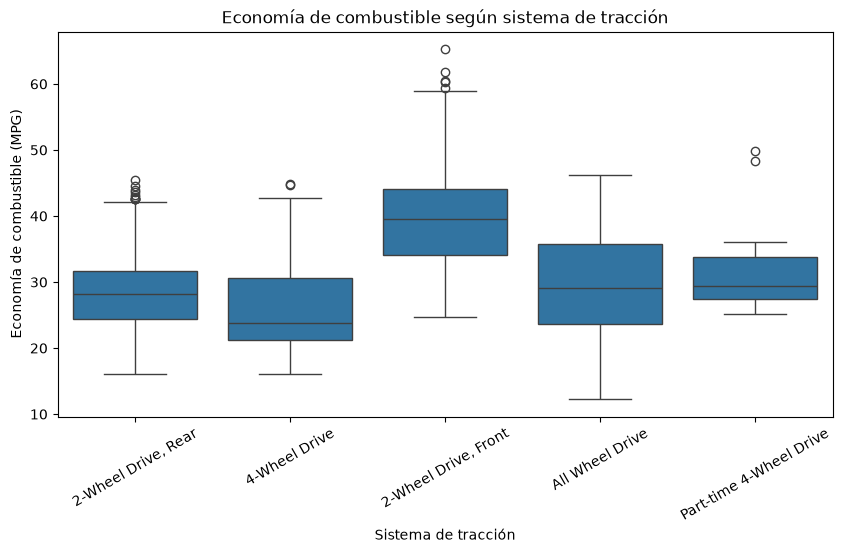

In [82]:
# Filtramos los vehículos a combustión y quitamos los registros que no tengan información de MPG o de tracción. 
df_traccion = df_limpio[df_limpio[col_combustible].isin(combustibles_combustion)].copy()

df_traccion = df_traccion.dropna(subset=[col_mpg, col_sistema_traccion])

# Agrupamos los registros que pertenecen a una misma configuración de vehículo y calculamos su MPG promedio.
df_traccion = (
    df_traccion.groupby([
        "Veh Mfr Code",
        "Test Vehicle ID",
        "Test Veh Configuration #",
        col_sistema_traccion
    ], as_index=False)
    .agg(MPG=(col_mpg, "mean"))
)

plt.figure(figsize=(10, 5))

sns.boxplot(data=df_traccion,x=col_sistema_traccion, y="MPG")

plt.title("Economía de combustible según sistema de tracción")
plt.xlabel("Sistema de tracción")
plt.ylabel("Economía de combustible (MPG)")
plt.xticks(rotation=30)
plt.show()

In [83]:
# Evaluamos la normalidad grupo por grupo (según el sistema de tracción) usando la prueba de Shapiro-Wilk

for nombre, grupo in df_traccion.groupby(col_sistema_traccion):
    stat, p = shapiro(grupo["MPG"])
    print(f"{nombre}:      estadístico={stat:.4f},     p-valor={p:.4f}")

2-Wheel Drive, Front:      estadístico=0.9772,     p-valor=0.0000
2-Wheel Drive, Rear:      estadístico=0.9694,     p-valor=0.0000
4-Wheel Drive:      estadístico=0.9037,     p-valor=0.0000
All Wheel Drive:      estadístico=0.9826,     p-valor=0.0012
Part-time 4-Wheel Drive:      estadístico=0.7782,     p-valor=0.0049


Los grupos no cumplen con el supuesto de normalidad --> continuamos con Kruskal-Wallis

In [ ]:
# kruskal-wallis para comparar la economía de combustible entre los cinco sistemas de tracción.

grupos = [                                                                      
    grupo["MPG"].values
    for _, grupo in df_traccion.groupby(col_sistema_traccion)             
]

estadistico, p_valor = kruskal(*grupos)

print("Estadístico:", estadistico)
print("P-valor:", p_valor)

if p_valor < 0.05:
    print("Se rechaza H0: existen diferencias significativas entre los sistemas de tracción.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de diferencias.")

Estadístico: 422.1869146118341
P-valor: 4.46481632751714e-90
Se rechaza H0: existen diferencias significativas entre los sistemas de tracción.


#

<div style="background-color: #b48593; padding: 10px; border-left: 5px solid #6f1e0c; border-radius: 4px; color: #333;"> 
<strong> Hipótesis (c): " Entre vehículos a combustión, las características técnicas del vehículo (peso, potencia, cilindrada, número de cilindros, transmisión y sistema de tracción) se encuentran asociadas conjuntamente con su eficiencia de combustible urbana. "
</div>

In [85]:
#Preparamos el conjunto de datos 

columnas_seleccionadas = [
    "RND_ADJ_FE",
    col_peso,
    col_hp,
    col_cilindrada,
    col_cantCilindros,
    col_transmision,
    col_sistema_traccion
]

df_c = df_limpio[
    (df_limpio[col_combustible].isin(combustibles_combustion)) &
    (df_limpio["Test Category"] == "FTP")
][columnas_seleccionadas].copy()

display(df_c)

,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type,Drive System Description
0,18.3,4500,680.0,4.000,8.0,Automatic,"2-Wheel Drive, Rear"
2,18.5,5500,707.0,4.000,8.0,Automatic,4-Wheel Drive
4,16.4,4500,825.0,5.200,12.0,Automatic,"2-Wheel Drive, Rear"
6,19.1,4250,665.0,4.000,8.0,Automatic,"2-Wheel Drive, Rear"
8,34.3,3750,255.0,2.000,NaN,Semi-Automatic,"2-Wheel Drive, Rear"
...,...,...,...,...,...,...,...
4250,29.5,4500,247.0,1.969,4.0,Semi-Automatic,"2-Wheel Drive, Front"
4253,36.1,5000,312.0,1.969,4.0,Semi-Automatic,All Wheel Drive
4255,30.0,5000,247.0,1.969,4.0,Semi-Automatic,"2-Wheel Drive, Front"
4258,25.9,5000,295.0,1.969,4.0,Semi-Automatic,"2-Wheel Drive, Front"


In [86]:
# Limpiamos los valores nulos de las variables seleccionadas

df_c = df_c.dropna()

print("Cantidad de registros después de eliminar nulos:", len(df_c))


Cantidad de registros después de eliminar nulos: 1536


In [87]:
# Preparamos las variables categóricas para el modelo de regresión lineal múltiple mediante One-Hot Encoding.

df_c = pd.get_dummies(df_c,
    columns=[
        col_transmision,
        col_sistema_traccion
    ],
    drop_first=True,
    dtype=int
)

display(df_c.head())

print("Cantidad de variables:", len(df_c.columns))

,RND_ADJ_FE,Equivalent Test Weight (lbs.),Rated Horsepower,Test Veh Displacement (L),# of Cylinders and Rotors,Tested Transmission Type_Automated Manual- Selectable (e.g. Automated Manual with paddles),Tested Transmission Type_Automatic,Tested Transmission Type_Continuously Variable,Tested Transmission Type_Manual,Tested Transmission Type_Selectable Continuously Variable (e.g. CVT with paddles),Tested Transmission Type_Semi-Automatic,"Drive System Description_2-Wheel Drive, Rear",Drive System Description_4-Wheel Drive,Drive System Description_All Wheel Drive,Drive System Description_Part-time 4-Wheel Drive
0,18.3,4500,680.0,4.0,8.0,0,1,0,0,0,0,1,0,0,0
2,18.5,5500,707.0,4.0,8.0,0,1,0,0,0,0,0,1,0,0
4,16.4,4500,825.0,5.2,12.0,0,1,0,0,0,0,1,0,0,0
6,19.1,4250,665.0,4.0,8.0,0,1,0,0,0,0,1,0,0,0
10,31.8,3875,255.0,2.0,4.0,0,0,0,0,0,1,0,0,1,0


Cantidad de variables: 15


In [ ]:
# Construimos el modelo de regresión lineal múltiple para predecir la economía de combustible (RND_ADJ_FE) en función de las variables seleccionadas.

Y = df_c[col_mpg]
X = df_c.drop(columns=[col_mpg])

X = sm.add_constant(X)

modelo = sm.OLS(Y, X).fit()

print(modelo.summary())


                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.692
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                     244.1
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:15:37   Log-Likelihood:                -4912.2
No. Observations:                1536   AIC:                             9854.
Df Residuals:                    1521   BIC:                             9934.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                                                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

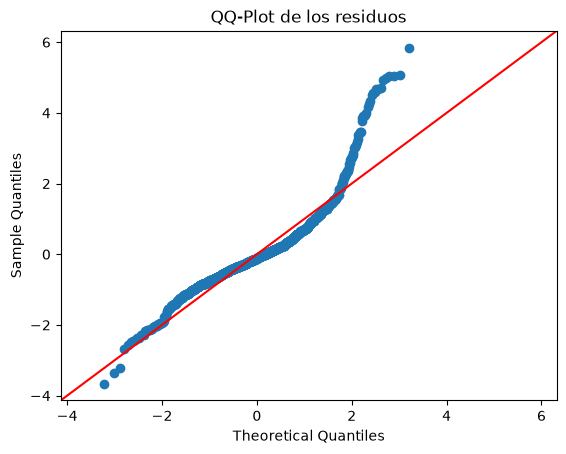

In [89]:
#QQ-Plot de los residuos

sm.qqplot(modelo.resid, line="45", fit=True)

plt.title("QQ-Plot de los residuos")
plt.show()

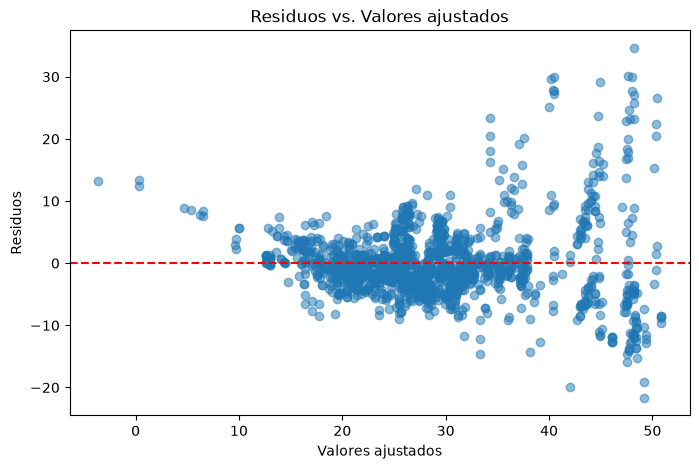

In [ ]:
# residuos vs. valores ajustados

plt.figure(figsize=(8, 5))

plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs. Valores ajustados")

plt.show()